# Parte Específica — EDA do Pump it Up

Projeto Final AVD 2026.2 — Grupo 6. Responsável: **Gustavo**.

Dataset: [Pump it Up: Data Mining the Water Table (DrivenData)](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/). Classe: `status_group` (`functional`, `functional needs repair`, `non functional`).

> **Sobre o uso de IA neste notebook:** as células de código marcadas com `# [IA]` foram geradas com apoio de IA para *tornar a análise possível* (cálculos, tabelas e gráficos). Toda interpretação, discussão e decisão de tratamento é autoral do grupo e fica nas células "Interpretação autoral".

## Índice e como ler este notebook

- [0. Pergunta de pesquisa e público-alvo](#secao-0)
- [Configuração](#secao-1)
- [Carga dos dados](#secao-2)
- [1. Análise Estrutural](#secao-3)
- [2. Qualidade dos dados e mecanismo de ausência](#secao-4)
- [3. Análise Distribucional](#secao-5)
- [4. Análise Relacional (com `status_group`)](#secao-6)
- [5. Outliers](#secao-7)
- [6. Tratamento e exportação](#secao-8)
- [7. Síntese da EDA](#secao-9)

**Legenda**
- `# [IA]` no início de uma célula de código: o código foi feito com apoio de IA (cálculos, tabelas e gráficos).
- `> **Como ler:**` antes de um gráfico ou tabela: explica só como se lê o resultado, sem interpretá-lo.
- `> **[Interpretação autoral — preencher]**`: a interpretação é do grupo e fica em branco até ser escrita.

**Para ler só os resultados (sem o código)**, gere uma página HTML na raiz do projeto:

```
jupyter nbconvert --to html --no-input src/parte_especifica/eda.ipynb --output-dir out/parte_especifica --output eda_leitura
```

**Aparência dos gráficos:** na célula de configuração, `TEMA_ESCURO = True` deixa os gráficos com fundo escuro. Volte para `False` antes de gerar as figuras do relatório.

<a id="secao-0"></a>

## 0. Pergunta de pesquisa e público-alvo

**Pergunta (versão inicial):** *Can you predict which water pumps are faulty?*

**Público-alvo:** gestor público (ex.: Ministério da Água da Tanzânia).

### ✅ [AUTORAL] 0.1 Definição final da pergunta e público-alvo

> **Público-alvo:** Gestores do Ministério de Águas da Tanzânia.

> **Pergunta final:** "Quais características de um ponto d'água se associam ao seu estado operacional (funcional, precisando de reparo ou não funcional) e em que medida esses atributos permitem classificar/identificar corretamente bombas com necessidade de manutenção ou inoperantes?"

<a id="secao-1"></a>

## Configuração

**Rodando no Google Colab?** O Colab só baixa este arquivo `.ipynb`, não a pasta `data/`. A célula abaixo clona o repositório e entra na pasta certa. Fora do Colab ela não faz nada.

In [1]:
# [IA] Claude Code – prepara o ambiente quando o notebook roda no Google Colab (clona o repositório)
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO = "projeto-avd-2026-2-pump-it-up-classificatorio"
    destino = f"/content/{REPO}"
    if not os.path.isdir(destino):
        subprocess.run(["git", "clone", "-q", f"https://github.com/Fyre-Flye/{REPO}.git", destino], check=True)
    os.chdir(f"{destino}/src/parte_especifica")
    print("Colab: repositório clonado, pasta de trabalho =", os.getcwd())

In [2]:
# [IA] Claude Code – configuração (imports, caminhos, cores da classe e função para salvar figuras)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Sobe pastas até achar a raiz do repositório (onde está o requirements.txt),
# para o notebook funcionar não importa de onde o Jupyter foi aberto.
ROOT = Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "parte_especifica"
OUT_DIR = ROOT / "out" / "parte_especifica"
if not (DATA_DIR / "raw" / "pump_it_up_train.csv").exists():
    raise FileNotFoundError(
        "Não achei data/parte_especifica/raw/pump_it_up_train.csv. Abra o notebook de dentro do repositório clonado "
        "(no Google Colab, rode antes a célula de clonagem).")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Aparência (mude aqui se quiser) ---------------------------------------------
TEMA_ESCURO = False  # True = gráficos com fundo escuro, para quem lê no Jupyter escuro.
                     # Volte para False antes de gerar as figuras do relatório (PNG em fundo branco).
if TEMA_ESCURO:
    plt.style.use("dark_background")
    sns.set_theme(style="darkgrid", rc={"axes.facecolor": "#1f1f1f", "figure.facecolor": "#161616"})
else:
    sns.set_theme(style="whitegrid")

# Fontes maiores, para ler sem esforço
plt.rcParams.update({
    "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "figure.dpi": 110,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Ordem e cores fixas da classe, para todos os gráficos da EDA lerem igual.
# Paleta Okabe-Ito, legível para pessoas com daltonismo (acessibilidade de cores, Aula 05).
# Pode trocar à vontade.
STATUS_ORDEM = ["functional", "functional needs repair", "non functional"]
STATUS_CORES = {
    "functional": "#0072B2",
    "functional needs repair": "#E69F00",
    "non functional": "#D55E00",
}


def salvar(fig, nome):
    """Salva a figura em out/parte_especifica/<nome>.png (com retry para travas do OneDrive)."""
    import time
    destino = OUT_DIR / f"{nome}.png"
    for tentativa in range(5):
        try:
            fig.savefig(destino, dpi=150, bbox_inches="tight")
            return
        except OSError:
            if tentativa == 4:
                raise
            time.sleep(0.5)



# [IA] Gemini – dicionário de glossário das colunas (baseado em docs/GLOSSARIO.md, sem interpretar dados)
GLOSSARIO_COLUNAS = {
    "id": "Identificador único da linha",
    "amount_tsh": "Total static head: água disponível no ponto (unidade a confirmar)",
    "date_recorded": "Data de registro da linha (2002 a 2013)",
    "funder": "Quem financiou o poço",
    "gps_height": "Altitude do poço (unidade a confirmar)",
    "installer": "Organização que instalou o poço",
    "longitude": "Coordenada GPS (longitude)",
    "latitude": "Coordenada GPS (latitude)",
    "wpt_name": "Nome do ponto d'água, se houver",
    "num_private": "Sem descrição oficial (a confirmar)",
    "basin": "Bacia hidrográfica",
    "subvillage": "Localização geográfica (nível a confirmar)",
    "region": "Localização geográfica — região",
    "region_code": "Código da região (nem sempre 1 a 1 com region)",
    "district_code": "Código do distrito",
    "lga": "Localização geográfica — lga (nível a confirmar)",
    "ward": "Localização geográfica — ward (nível a confirmar)",
    "population": "População ao redor do poço",
    "public_meeting": "Verdadeiro/Falso (significado a confirmar)",
    "recorded_by": "Grupo que registrou a linha (valor único)",
    "scheme_management": "Quem opera o ponto d'água",
    "scheme_name": "Quem opera o ponto d'água / nome do esquema",
    "permit": "Se o ponto d'água tem permissão (licença)",
    "construction_year": "Ano de construção do ponto d'água",
    "extraction_type": "Tipo de extração usado (nível detalhado)",
    "extraction_type_group": "Tipo de extração usado (nível intermediário)",
    "extraction_type_class": "Tipo de extração usado (nível geral)",
    "management": "Como o ponto d'água é gerido (nível detalhado)",
    "management_group": "Como o ponto d'água é gerido (nível agrupado)",
    "payment": "O que a água custa (nível detalhado)",
    "payment_type": "O que a água custa (rótulos curtos)",
    "water_quality": "Qualidade da água (nível detalhado)",
    "quality_group": "Qualidade da água (nível agrupado)",
    "quantity": "Quantidade de água",
    "quantity_group": "Quantidade de água (idêntica a quantity)",
    "source": "Fonte da água (nível detalhado)",
    "source_type": "Fonte da água (nível intermediário)",
    "source_class": "Fonte da água (nível geral)",
    "waterpoint_type": "Tipo de ponto d'água (nível detalhado)",
    "waterpoint_type_group": "Tipo de ponto d'água (nível agrupado)",
    "status_group": "Variável-alvo: situação funcional do ponto d'água",
    "idade_no_registro": "Derivada: ano do registro menos construction_year",
}


def glossario(col):
    """Retorna a definição curta da coluna segundo docs/GLOSSARIO.md."""
    return GLOSSARIO_COLUNAS.get(col, "")


def com_titulo(obj, titulo):
    """Aplica título (caption) legível em DataFrame ou Styler do pandas."""
    styler = obj.style if isinstance(obj, pd.DataFrame) else obj
    return styler.set_caption(titulo).set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "14px"), ("font-weight", "bold"), ("text-align", "left"), ("padding", "4px 0 8px 0")],
    }], overwrite=False)

print("Raiz do projeto encontrada:", ROOT.name)

Raiz do projeto encontrada: projeto-avd-2026-2-pump-it-up-classificatorio


<a id="secao-2"></a>

## Carga dos dados

In [3]:
# [IA] Claude Code – leitura do dataset bruto (df_raw nunca é alterado)
df_raw = pd.read_csv(DATA_DIR / "raw" / "pump_it_up_train.csv")
df = df_raw.copy()
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")
com_titulo(df.head(), "Tabela 0 — Amostra inicial do dataset bruto (5 primeiras linhas)")

59,400 linhas x 41 colunas


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,basin,subvillage,region,region_code,district_code,lga,ward,population,public_meeting,recorded_by,scheme_management,scheme_name,permit,construction_year,extraction_type,extraction_type_group,extraction_type_class,management,management_group,payment,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.000000,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,Lake Nyasa,Mnyusi B,Iringa,11,5,Ludewa,Mundindi,109,True,GeoData Consultants Ltd,VWC,Roman,False,1999,gravity,gravity,gravity,vwc,user-group,pay annually,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.000000,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,Lake Victoria,Nyamara,Mara,20,2,Serengeti,Natta,280,nan,GeoData Consultants Ltd,Other,nan,True,2010,gravity,gravity,gravity,wug,user-group,never pay,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.000000,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,Pangani,Majengo,Manyara,21,4,Simanjiro,Ngorika,250,True,GeoData Consultants Ltd,VWC,Nyumba ya mungu pipe scheme,True,2009,gravity,gravity,gravity,vwc,user-group,pay per bucket,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.000000,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,Ruvuma / Southern Coast,Mahakamani,Mtwara,90,63,Nanyumbu,Nanyumbu,58,True,GeoData Consultants Ltd,VWC,nan,True,1986,submersible,submersible,submersible,vwc,user-group,never pay,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.000000,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,Lake Victoria,Kyanyamisa,Kagera,18,1,Karagwe,Nyakasimbi,0,True,GeoData Consultants Ltd,nan,nan,True,0,gravity,gravity,gravity,other,other,never pay,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


### Valores distintos das colunas-chave

Lista cada valor com a contagem de linhas (`value_counts`), incluindo os faltantes (`NaN`). Só as colunas com poucos valores: as de muitos valores (`wpt_name`, `subvillage`, `funder`, `installer`, `scheme_name`, `ward`, `lga`) ficam de fora. O significado dos valores está em `docs/GLOSSARIO.md`.

In [4]:
# [IA] Claude Code + Gemini – lista os valores distintos das colunas-chave (com significado do glossário)
COLS_CHAVE = [
    # alvo
    "status_group",
    # poucas categorias, já agrupadas
    "quantity", "management_group", "quality_group", "source_class",
    "extraction_type_class", "payment_type", "waterpoint_type_group", "basin",
    # com faltantes
    "public_meeting", "permit", "scheme_management",
]

for col in COLS_CHAVE:
    contagem = df[col].value_counts(dropna=False)   # dropna=False mostra também os faltantes (NaN)
    print(f"{col} ({glossario(col)}): {df[col].nunique()} valores distintos")
    print(contagem.to_string())
    print()

status_group (Variável-alvo: situação funcional do ponto d'água): 3 valores distintos
status_group
functional                 32259
non functional             22824
functional needs repair     4317

quantity (Quantidade de água): 5 valores distintos
quantity
enough          33186
insufficient    15129
dry              6246
seasonal         4050
unknown           789

management_group (Como o ponto d'água é gerido (nível agrupado)): 5 valores distintos
management_group
user-group    52490
commercial     3638
parastatal     1768
other           943
unknown         561

quality_group (Qualidade da água (nível agrupado)): 6 valores distintos
quality_group
good        50818
salty        5195
unknown      1876
milky         804
colored       490
fluoride      217

source_class (Fonte da água (nível geral)): 3 valores distintos
source_class
groundwater    45794
surface        13328
unknown          278

extraction_type_class (Tipo de extração usado (nível geral)): 7 valores distintos
extracti

<a id="secao-3"></a>

## 1. Análise Estrutural

Tipos, dimensões, cardinalidade, duplicados, colunas constantes, colunas redundantes e consistência dos textos.

### 1.1 Visão geral das colunas, grupos e duplicatas

Resume a estrutura de todas as 41 colunas do dataset (significado, tipo, quantidade de valores únicos, nulos e um exemplo), separa as colunas em grupos e verifica linhas duplicadas e colunas constantes.

> **Como ler:** Cada linha é uma coluna do dataset. A barra azul mostra quantos valores distintos ela tem. O vermelho mostra o percentual de nulos: quanto mais escuro, mais nulos.

In [5]:
# [IA] Claude Code + Gemini – visão geral de cada coluna (com coluna glossario)
resumo = pd.DataFrame({
    "glossario": [glossario(c) for c in df.columns],
    "tipo_pandas": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "exemplo": df.iloc[0],
})
com_titulo(
    resumo.sort_values("n_unicos").style.bar(subset=["n_unicos"], color="#9ecae1").background_gradient(
        subset=["pct_nulos"], cmap="Reds", vmin=0, vmax=100).format(
        {"n_unicos": "{:,.0f}", "n_nulos": "{:,.0f}", "pct_nulos": "{:.2f}%"}),
    "Tabela 1.1 — Visão geral das 41 colunas do dataset"
)

,glossario,tipo_pandas,n_unicos,n_nulos,pct_nulos,exemplo
recorded_by,Grupo que registrou a linha (valor único),str,1,0,0.00%,GeoData Consultants Ltd
public_meeting,Verdadeiro/Falso (significado a confirmar),object,2,"3,334",5.61%,True
permit,Se o ponto d'água tem permissão (licença),object,2,"3,056",5.14%,False
source_class,Fonte da água (nível geral),str,3,0,0.00%,groundwater
status_group,Variável-alvo: situação funcional do ponto d'água,str,3,0,0.00%,functional
quantity_group,Quantidade de água (idêntica a quantity),str,5,0,0.00%,enough
quantity,Quantidade de água,str,5,0,0.00%,enough
management_group,Como o ponto d'água é gerido (nível agrupado),str,5,0,0.00%,user-group
quality_group,Qualidade da água (nível agrupado),str,6,0,0.00%,good
waterpoint_type_group,Tipo de ponto d'água (nível agrupado),str,6,0,0.00%,communal standpipe


In [6]:
# [IA] Claude Code – separação das colunas em grupos usados no resto do notebook
COL_ID = "id"
COL_ALVO = "status_group"

# Medidas quantitativas
COLS_NUM = ["amount_tsh", "gps_height", "longitude", "latitude",
            "num_private", "population", "construction_year"]
# Numéricas no arquivo, mas são códigos de localização (na prática, qualitativas)
COLS_CODIGO = ["region_code", "district_code"]
COLS_DATA = ["date_recorded"]
# Todo o resto (exceto id e alvo) é qualitativo
COLS_CAT = [c for c in df.columns
            if c not in COLS_NUM + COLS_CODIGO + COLS_DATA + [COL_ID, COL_ALVO]]

print(f"Quantitativas ({len(COLS_NUM)}): {COLS_NUM}")
print(f"Códigos numéricos ({len(COLS_CODIGO)}): {COLS_CODIGO}")
print(f"Data ({len(COLS_DATA)}): {COLS_DATA}")
print(f"Qualitativas ({len(COLS_CAT)}): {COLS_CAT}")

Quantitativas (7): ['amount_tsh', 'gps_height', 'longitude', 'latitude', 'num_private', 'population', 'construction_year']
Códigos numéricos (2): ['region_code', 'district_code']
Data (1): ['date_recorded']
Qualitativas (29): ['funder', 'installer', 'wpt_name', 'basin', 'subvillage', 'region', 'lga', 'ward', 'public_meeting', 'recorded_by', 'scheme_management', 'scheme_name', 'permit', 'extraction_type', 'extraction_type_group', 'extraction_type_class', 'management', 'management_group', 'payment', 'payment_type', 'water_quality', 'quality_group', 'quantity', 'quantity_group', 'source', 'source_type', 'source_class', 'waterpoint_type', 'waterpoint_type_group']


In [7]:
# [IA] Claude Code – linhas duplicadas, ids repetidos e colunas com um único valor
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("Linhas duplicadas (ignorando o id):", df.drop(columns=COL_ID).duplicated().sum())
print("Ids repetidos:", df[COL_ID].duplicated().sum())

constantes = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Colunas com um único valor:", constantes)
for c in constantes:
    print(f"  {c}: {df[c].unique()}")

Linhas duplicadas (todas as colunas): 0


Linhas duplicadas (ignorando o id):

 36
Ids repetidos: 0
Colunas com um único valor: ['recorded_by']
  recorded_by: <StringArray>
['GeoData Consultants Ltd']
Length: 1, dtype: str


### 1.2 Colunas redundantes (famílias)

Várias colunas aparecem em "famílias" (ex.: `extraction_type`, `extraction_type_group`, `extraction_type_class`). A tabela abaixo verifica, para cada par, se a coluna mais geral é só um agrupamento da mais detalhada: cada categoria da detalhada cai sempre em **uma única** categoria da geral.

> **Como ler:** Cada linha compara duas colunas da mesma família. `True` na última coluna quer dizer que a coluna mais geral só agrupa a detalhada: cada categoria da detalhada cai em uma única categoria da geral.

In [8]:
# [IA] Claude Code + Gemini – verifica se as colunas "irmãs" são agrupamentos umas das outras (com glossario)
FAMILIAS = {
    "extraction_type": ["extraction_type", "extraction_type_group", "extraction_type_class"],
    "quantity": ["quantity", "quantity_group"],
    "payment": ["payment", "payment_type"],
    "water_quality": ["water_quality", "quality_group"],
    "source": ["source", "source_type", "source_class"],
    "waterpoint_type": ["waterpoint_type", "waterpoint_type_group"],
    "management": ["management", "management_group"],
}

linhas = []
for familia, cols in FAMILIAS.items():
    for detalhada, geral in zip(cols[:-1], cols[1:]):
        # maior nº de categorias "gerais" associadas a uma mesma categoria "detalhada"
        max_gerais = df.groupby(detalhada, dropna=False)[geral].nunique(dropna=False).max()
        linhas.append({
            "familia": familia,
            "glossario": glossario(familia),
            "detalhada": detalhada,
            "geral": geral,
            "n_cat_detalhada": df[detalhada].nunique(),
            "n_cat_geral": df[geral].nunique(),
            "geral_e_agrupamento_da_detalhada": max_gerais == 1,
        })
com_titulo(pd.DataFrame(linhas), "Tabela 1.2 — Famílias de colunas redundantes (detalhada vs. geral)")

,familia,glossario,detalhada,geral,n_cat_detalhada,n_cat_geral,geral_e_agrupamento_da_detalhada
0,extraction_type,Tipo de extração usado (nível detalhado),extraction_type,extraction_type_group,18,13,True
1,extraction_type,Tipo de extração usado (nível detalhado),extraction_type_group,extraction_type_class,13,7,True
2,quantity,Quantidade de água,quantity,quantity_group,5,5,True
3,payment,O que a água custa (nível detalhado),payment,payment_type,7,7,True
4,water_quality,Qualidade da água (nível detalhado),water_quality,quality_group,8,6,True
5,source,Fonte da água (nível detalhado),source,source_type,10,7,True
6,source,Fonte da água (nível detalhado),source_type,source_class,7,3,True
7,waterpoint_type,Tipo de ponto d'água (nível detalhado),waterpoint_type,waterpoint_type_group,7,6,True
8,management,Como o ponto d'água é gerido (nível detalhado),management,management_group,12,5,True


#### 1.2.1 Exemplos lado a lado (`quantity` e `payment`)

Cruza lado a lado duas famílias redundantes (`quantity` × `quantity_group` e `payment` × `payment_type`) para mostrar a correspondência exata entre os rótulos.

> **Como ler:** As linhas são os valores de uma coluna e as colunas são os valores da outra. O número é a quantidade de pontos d'água em cada cruzamento; quanto mais escuro, mais linhas.

In [9]:
# [IA] Claude Code – exemplos lado a lado: como as categorias se correspondem
display(com_titulo(pd.crosstab(df["quantity"], df["quantity_group"]).style.background_gradient(cmap="Blues", axis=None), "Tabela 1.2a — Correspondência: quantity × quantity_group"))
display(com_titulo(pd.crosstab(df["payment"], df["payment_type"]).style.background_gradient(cmap="Blues", axis=None), "Tabela 1.2b — Correspondência: payment × payment_type"))

quantity_group,dry,enough,insufficient,seasonal,unknown
quantity,,,,,
dry,6246,0,0,0,0
enough,0,33186,0,0,0
insufficient,0,0,15129,0,0
seasonal,0,0,0,4050,0
unknown,0,0,0,0,789


payment_type,annually,monthly,never pay,on failure,other,per bucket,unknown
payment,,,,,,,
never pay,0,0,25348,0,0,0,0
other,0,0,0,0,1054,0,0
pay annually,3642,0,0,0,0,0,0
pay monthly,0,8300,0,0,0,0,0
pay per bucket,0,0,0,0,0,8985,0
pay when scheme fails,0,0,0,3914,0,0,0
unknown,0,0,0,0,0,0,8157


### 1.3 Consistência entre `region` e `region_code`

> **Como ler:** A primeira lista mostra as regiões com mais de um `region_code`. A segunda, os códigos com mais de uma região. Lista vazia quer dizer que não há essa repetição.

In [10]:
# [IA] Claude Code – quantos códigos existem por região e quantas regiões por código
codigos_por_regiao = df.groupby("region")["region_code"].unique().apply(sorted)
print("Regiões com mais de um region_code:")
display(codigos_por_regiao[codigos_por_regiao.apply(len) > 1])

regioes_por_codigo = df.groupby("region_code")["region"].unique().apply(sorted)
print("region_code com mais de uma região:")
display(regioes_por_codigo[regioes_por_codigo.apply(len) > 1])

Regiões com mais de um region_code:


region
Arusha            [2, 24]
Lindi         [8, 18, 80]
Mtwara        [9, 90, 99]
Mwanza           [17, 19]
Pwani         [6, 40, 60]
Shinyanga    [11, 14, 17]
Tanga              [4, 5]
Name: region_code, dtype: object

region_code com mais de uma região:


region_code
5       [Morogoro, Tanga]
11    [Iringa, Shinyanga]
14    [Shinyanga, Tabora]
17    [Mwanza, Shinyanga]
18        [Kagera, Lindi]
Name: region, dtype: object

### 1.4 Alta cardinalidade e grafias diferentes do mesmo nome

In [11]:
# [IA] Claude Code + Gemini – nº de categorias antes e depois de padronizar maiúsculas/espaços (com glossario)
linhas = []
for col in ["funder", "installer", "wpt_name", "subvillage", "scheme_name", "ward", "lga"]:
    s = df[col].dropna().astype(str)
    linhas.append({
        "coluna": col,
        "glossario": glossario(col),
        "n_unicos": s.nunique(),
        "n_unicos_minusculo_sem_espacos": s.str.strip().str.lower().nunique(),
        "top_5": s.value_counts().head(5).to_dict(),
    })
com_titulo(pd.DataFrame(linhas), "Tabela 1.4 — Alta cardinalidade antes e depois de strip().lower()")

,coluna,glossario,n_unicos,n_unicos_minusculo_sem_espacos,top_5
0,funder,Quem financiou o poço,1896,1896,"{'Government Of Tanzania': 9084, 'Danida': 3114, 'Hesawa': 2202, 'Rwssp': 1374, 'World Bank': 1349}"
1,installer,Organização que instalou o poço,2145,1935,"{'DWE': 17402, 'Government': 1825, 'RWE': 1206, 'Commu': 1060, 'DANIDA': 1050}"
2,wpt_name,"Nome do ponto d'água, se houver",37399,37399,"{'none': 3563, 'Shuleni': 1748, 'Zahanati': 830, 'Msikitini': 535, 'Kanisani': 323}"
3,subvillage,Localização geográfica (nível a confirmar),19287,19287,"{'Madukani': 508, 'Shuleni': 506, 'Majengo': 502, 'Kati': 373, 'Mtakuja': 262}"
4,scheme_name,Quem opera o ponto d'água / nome do esquema,2695,2576,"{'K': 682, 'Borehole': 546, 'Chalinze wate': 405, 'M': 400, 'DANIDA': 379}"
5,ward,Localização geográfica — ward (nível a confirmar),2092,2092,"{'Igosi': 307, 'Imalinyi': 252, 'Siha Kati': 232, 'Mdandu': 231, 'Nduruma': 217}"
6,lga,Localização geográfica — lga (nível a confirmar),125,125,"{'Njombe': 2503, 'Arusha Rural': 1252, 'Moshi Rural': 1251, 'Bariadi': 1177, 'Rungwe': 1106}"


### 1.5 Esquema de relacionamento das colunas

Mapa de como as colunas se agrupam e se derivam umas das outras. Os números são calculados a partir do dataset. Só descreve a **estrutura**; o que ela significa para a análise é interpretação do grupo.

> **Como ler:** **Figura 1:** cada caixa é um grupo de colunas e o número é quantas colunas ele tem; todos apontam para o alvo. **Figura 2:** cada linha é uma família de colunas; seta cheia = a coluna da direita agrupa a da esquerda em categorias mais gerais; seta tracejada = mesma informação com outro nome; o número é a quantidade de valores distintos. **Figura 3:** os níveis de localização, do mais geral ao mais detalhado; o texto ao lado de cada seta diz que fração dos valores cabe em um só valor do nível de cima; as caixas tracejadas são códigos que não casam um a um com os nomes.

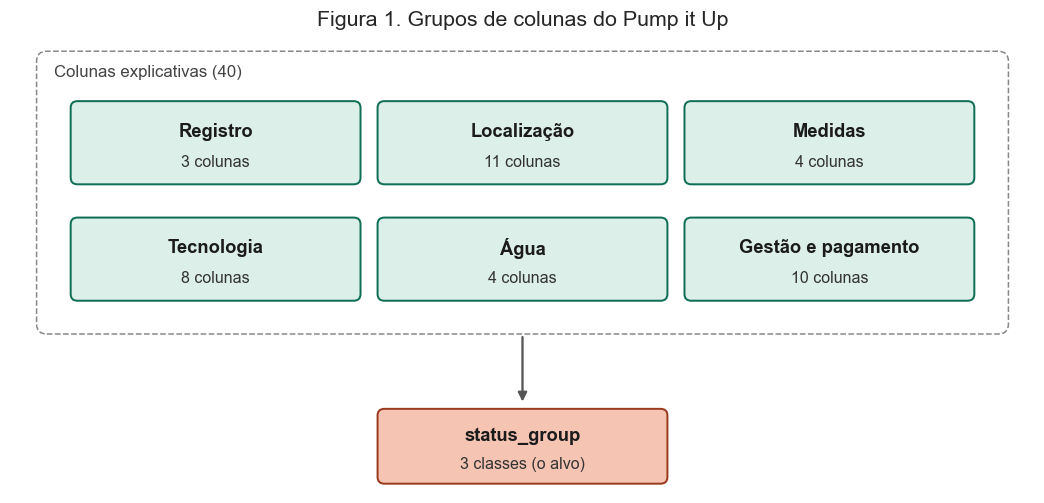

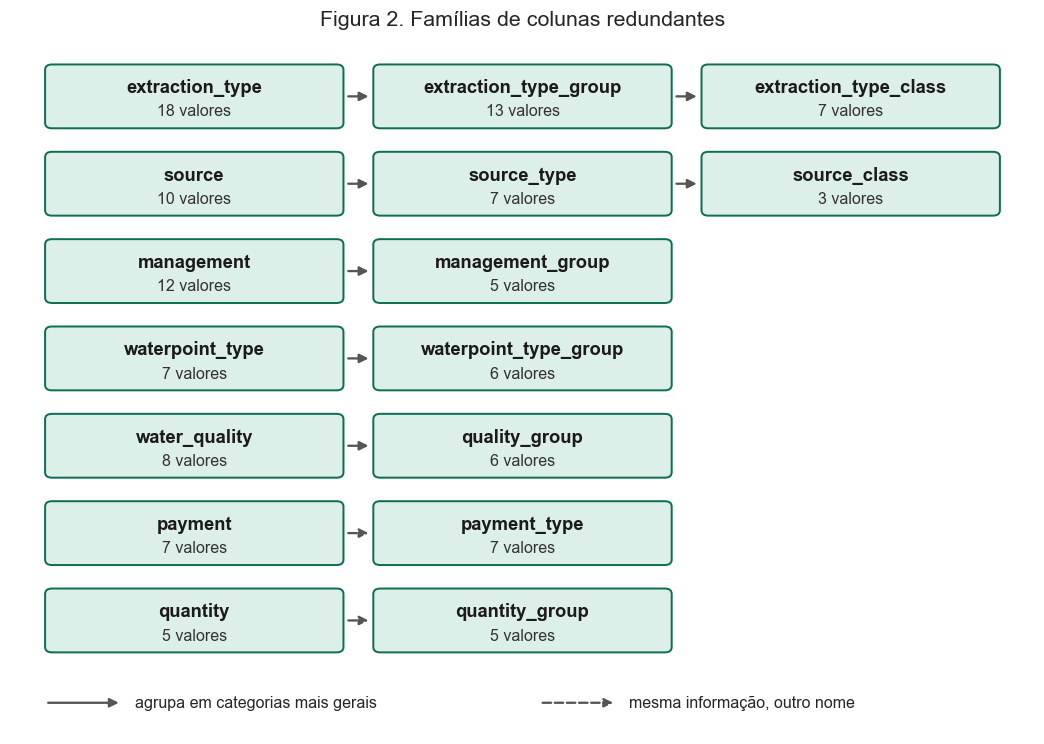

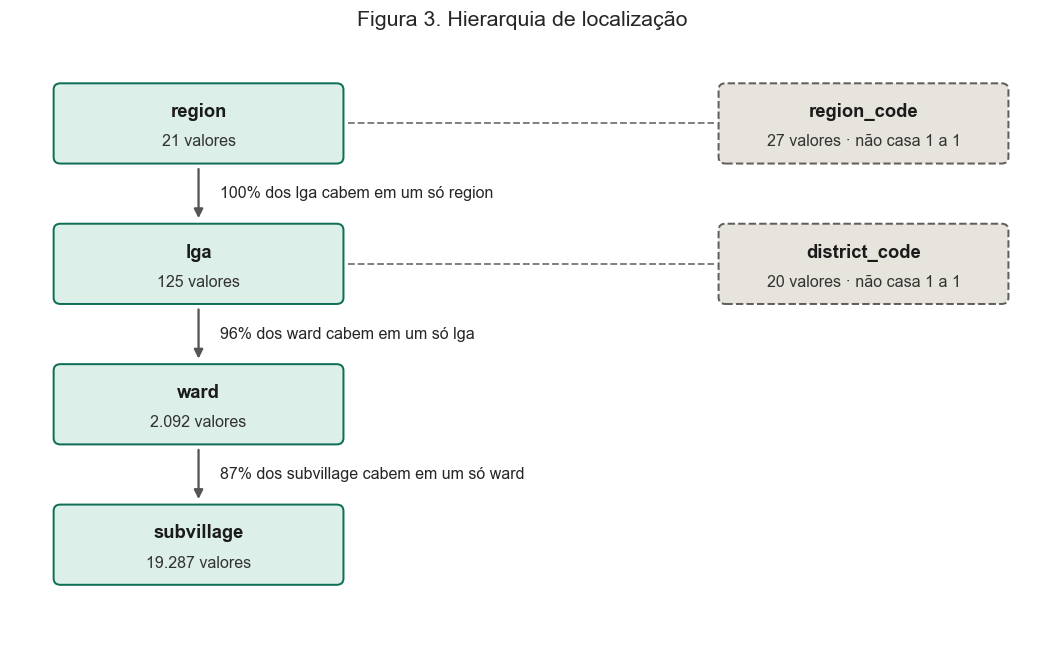

In [12]:
# [IA] Claude Code – esquema de relacionamento das colunas (3 figuras)
from matplotlib.patches import FancyBboxPatch

COR_BOX, COR_BORDA = "#DCEFE9", "#0F6E56"
COR_ALVO, COR_ALVO_BORDA = "#F5C4B3", "#993C1D"
COR_COD, COR_COD_BORDA = "#E6E4DC", "#5F5E5A"

GRUPOS = {
    "Registro": ["id", "date_recorded", "recorded_by"],
    "Localização": ["basin", "subvillage", "region", "region_code", "district_code", "lga", "ward",
                    "latitude", "longitude", "gps_height", "wpt_name"],
    "Medidas": ["amount_tsh", "population", "construction_year", "num_private"],
    "Tecnologia": ["extraction_type", "extraction_type_group", "extraction_type_class",
                   "source", "source_type", "source_class", "waterpoint_type", "waterpoint_type_group"],
    "Água": ["quantity", "quantity_group", "water_quality", "quality_group"],
    "Gestão e pagamento": ["funder", "installer", "management", "management_group", "scheme_management",
                           "scheme_name", "permit", "public_meeting", "payment", "payment_type"],
}
# confere que os grupos cobrem todas as colunas explicativas, sem repetir nenhuma
todas = sum(GRUPOS.values(), [])
assert len(todas) == len(set(todas)) and set(todas) == set(df.columns) - {COL_ALVO}


def caixa(ax, x, y, w, h, titulo, sub, cor=COR_BOX, borda=COR_BORDA, tracejada=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.08",
                                fc=cor, ec=borda, lw=1.3, ls="--" if tracejada else "-"))
    ax.text(x + w / 2, y + h * 0.64, titulo, ha="center", va="center", fontsize=12, fontweight="bold", color="#1b1b1b")
    ax.text(x + w / 2, y + h * 0.27, sub, ha="center", va="center", fontsize=10.5, color="#333333")


def seta(ax, x1, y1, x2, y2, tracejada=False):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#555555", ls="--" if tracejada else "-"))


# ---- Figura 1: grupos de colunas em volta do alvo
fig, ax = plt.subplots(figsize=(12, 5.4))
ax.set_xlim(0, 12); ax.set_ylim(-0.2, 5.3); ax.axis("off")
ax.add_patch(FancyBboxPatch((0.3, 1.7), 11.4, 3.4, boxstyle="round,pad=0,rounding_size=0.12",
                            fc="none", ec="#888888", lw=1, ls="--"))
ax.text(0.5, 4.85, f"Colunas explicativas ({len(todas)})", fontsize=11, color="#444444", va="center")
posicoes = [(0.7, 3.5), (4.3, 3.5), (7.9, 3.5), (0.7, 2.1), (4.3, 2.1), (7.9, 2.1)]
for (nome, cols), (x, y) in zip(GRUPOS.items(), posicoes):
    caixa(ax, x, y, 3.4, 1.0, nome, f"{len(cols)} colunas")
seta(ax, 6, 1.7, 6, 0.85)
caixa(ax, 4.3, -0.1, 3.4, 0.9, COL_ALVO, f"{df[COL_ALVO].nunique()} classes (o alvo)", COR_ALVO, COR_ALVO_BORDA)
ax.set_title("Figura 1. Grupos de colunas do Pump it Up", fontsize=14)
salvar(fig, "01_esquema_grupos")
plt.show()

# ---- Figura 2: famílias de colunas (mesma informação em níveis diferentes)
FAMILIAS = [
    (["extraction_type", "extraction_type_group", "extraction_type_class"], False),
    (["source", "source_type", "source_class"], False),
    (["management", "management_group"], False),
    (["waterpoint_type", "waterpoint_type_group"], False),
    (["water_quality", "quality_group"], False),
    (["payment", "payment_type"], True),
    (["quantity", "quantity_group"], True),
]
passo, alt = 1.3, 0.95
fig, ax = plt.subplots(figsize=(12, 0.95 * len(FAMILIAS) + 1.6))
ax.set_xlim(0, 12); ax.set_ylim(0, passo * len(FAMILIAS) + 1.3); ax.axis("off")
xs = [0.4, 4.25, 8.1]
for linha, (cols, so_renomeia) in enumerate(FAMILIAS):
    y = passo * (len(FAMILIAS) - 1 - linha) + 1.2
    for k, c in enumerate(cols):
        caixa(ax, xs[k], y, 3.5, alt, c, f"{df[c].nunique()} valores")
        if k > 0:
            seta(ax, xs[k - 1] + 3.5 + 0.02, y + alt / 2, xs[k] - 0.02, y + alt / 2, tracejada=so_renomeia)
seta(ax, 0.4, 0.45, 1.3, 0.45)
ax.text(1.45, 0.45, "agrupa em categorias mais gerais", va="center", fontsize=10.5)
seta(ax, 6.2, 0.45, 7.1, 0.45, tracejada=True)
ax.text(7.25, 0.45, "mesma informação, outro nome", va="center", fontsize=10.5)
ax.set_title("Figura 2. Famílias de colunas redundantes", fontsize=14)
salvar(fig, "01_esquema_familias")
plt.show()

# ---- Figura 3: hierarquia de localização
NIVEIS = ["region", "lga", "ward", "subvillage"]
fig, ax = plt.subplots(figsize=(12, 7.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 7.6); ax.axis("off")
ys = [6.0, 4.25, 2.5, 0.75]
for k, nivel in enumerate(NIVEIS):
    caixa(ax, 0.5, ys[k], 3.4, 1.0, nivel, f"{df[nivel].nunique():,} valores".replace(",", "."))
    if k > 0:
        pai = NIVEIS[k - 1]
        cabem = (df.groupby(nivel)[pai].nunique() == 1).mean() * 100
        seta(ax, 2.2, ys[k - 1] - 0.03, 2.2, ys[k] + 1.03)
        ax.text(2.45, (ys[k - 1] + ys[k] + 1.0) / 2, f"{cabem:.0f}% dos {nivel} cabem em um só {pai}", va="center", fontsize=10.5)
for nivel, cod, y in [("region", "region_code", 6.0), ("lga", "district_code", 4.25)]:
    ax.plot([3.95, 8.25], [y + 0.5, y + 0.5], color="#777777", lw=1.2, ls="--")
    caixa(ax, 8.3, y, 3.4, 1.0, cod, f"{df[cod].nunique()} valores · não casa 1 a 1", COR_COD, COR_COD_BORDA, tracejada=True)
ax.set_title("Figura 3. Hierarquia de localização", fontsize=14)
salvar(fig, "01_esquema_localizacao")
plt.show()

### ✅ [AUTORAL] 1.6 Interpretação — Análise Estrutural

> O dataset tem 59.400 linhas e 41 colunas, misturando variáveis quantitativas e qualitativas, com `status_group` como variável-alvo. Não existem linhas duplicadas considerando todas as colunas nem `id`s repetidos, mas existem 36 linhas duplicadas quando ignoramos o `id` (mesmos valores nas outras 40 colunas com `id`s diferentes), e isso vai precisar ser tratado na Seção 6.

> Também há muitas colunas redundantes e irrelevantes. Um exemplo claro é `recorded_by`, que tem um único valor em todas as 59.400 linhas (`GeoData Consultants Ltd`, o grupo que registrou os dados). No caso de `region_code` e `region`, 7 regiões aparecem com mais de um código e alguns códigos aparecem em mais de uma região, então faz muito mais sentido ficar com `region` para trabalhar as regiões da Tanzânia. Várias colunas vão sair na limpeza porque são só versões mais específicas ou mais gerais da mesma informação; a decisão aqui é ficar apenas com as versões generalizadas, o que reduz a quantidade de categorias e facilita a análise.

> A alta cardinalidade, principalmente quando há formas diferentes de escrever o mesmo nome (espaços, maiúsculas/minúsculas ou variações locais), costuma apontar erro de digitação ou falta de padrão de quem registrou. Isso é esperado por ser erro humano e atrapalha técnicas de encoding mais comuns, como o One-Hot Encoding. Seguindo o que foi visto na Aula 26, para as variáveis nominais de alta cardinalidade que continuarem na modelagem, a decisão é usar Target Encoding combinado ao `RandomForestClassifier`, sempre ajustado apenas no conjunto de treino para evitar data leakage.

> Testar a conversão dos textos com `strip().lower()` ajuda a enxergar essa falta de padronização na prática: nos dados, o número de categorias únicas caiu em 2 das 7 colunas testadas (`installer` foi de 2.145 para 1.935 e `scheme_name` foi de 2.695 para 2.576), sem mudar nada nas outras 5 (`funder`, `wpt_name`, `subvillage`, `ward` e `lga`). Ou seja, a limpeza textual ajuda só em parte e ainda exige uma decisão mais cuidadosa na hora de tratar essas colunas.

<a id="secao-4"></a>

## 2. Qualidade dos dados e mecanismo de ausência

Faltantes explícitos (`NaN`), zeros e códigos que podem esconder faltantes, e como a ausência se distribui (entre colunas, por região, por ano de registro e por classe). Essa é a base para discutir o mecanismo (MCAR, MAR ou MNAR, Aula 09) antes de decidir qualquer tratamento.

**Nada é alterado em `df` nesta seção.**

### 2.1 Faltantes explícitos (`NaN`)

Lista exclusivamente as colunas que possuem valores vazios explícitos (`NaN`) no arquivo bruto, com a contagem absoluta e o percentual sobre o total de registros.

> **Como ler:** Só aparecem colunas com `NaN`. `n_nulos` é a contagem e `pct` é o percentual das linhas; quanto maior a barra, mais faltantes.

In [13]:
# [IA] Claude Code + Gemini – faltantes explícitos (NaN, com coluna glossario)
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
com_titulo(
    pd.DataFrame({"glossario": [glossario(c) for c in nulos.index], "n_nulos": nulos, "pct": (nulos / len(df) * 100).round(2)}).style.bar(
        subset=["pct"], color="#f4a582", vmin=0, vmax=100).format({"n_nulos": "{:,.0f}", "pct": "{:.2f}%"}),
    "Tabela 2.1 — Faltantes explícitos (NaN) por coluna"
)

,glossario,n_nulos,pct
scheme_name,Quem opera o ponto d'água / nome do esquema,"28,810",48.50%
scheme_management,Quem opera o ponto d'água,"3,878",6.53%
installer,Organização que instalou o poço,"3,655",6.15%
funder,Quem financiou o poço,"3,637",6.12%
public_meeting,Verdadeiro/Falso (significado a confirmar),"3,334",5.61%
permit,Se o ponto d'água tem permissão (licença),"3,056",5.14%
subvillage,Localização geográfica (nível a confirmar),371,0.62%
wpt_name,"Nome do ponto d'água, se houver",2,0.00%


### 2.2 Zeros suspeitos, negativos e códigos disfarçados

Contabiliza ocorrências de zeros, valores negativos e códigos de texto (`'0'`, `'-'`) que podem estar escondendo dados ausentes em colunas onde esses valores são incomuns ou improváveis.

> **Como ler:** Cada linha é um valor que pode esconder um faltante (zero, negativo ou o código `0`/`-`). `n` é a contagem de linhas e `pct` o percentual do total.

In [14]:
# [IA] Claude Code + Gemini – zeros, valores negativos e códigos suspeitos (com coluna glossario)
suspeitos = {
    "population == 0": df["population"] == 0,
    "construction_year == 0": df["construction_year"] == 0,
    "gps_height == 0": df["gps_height"] == 0,
    "gps_height < 0": df["gps_height"] < 0,
    "longitude == 0": df["longitude"] == 0,
    # a Tanzânia inteira fica no hemisfério sul, então latitude ~0 é suspeita
    "latitude > -0.001": df["latitude"] > -0.001,
    "amount_tsh == 0": df["amount_tsh"] == 0,
    "num_private == 0": df["num_private"] == 0,
    "funder in {'0', '-'}": df["funder"].isin(["0", "-"]),
    "installer in {'0', '-'}": df["installer"].isin(["0", "-"]),
}
com_titulo(
    pd.DataFrame({
        "glossario": {k: glossario(k.split()[0]) for k in suspeitos},
        "n": {k: int(v.sum()) for k, v in suspeitos.items()},
        "pct": {k: round(v.mean() * 100, 2) for k, v in suspeitos.items()},
    }).style.bar(subset=["pct"], color="#f4a582", vmin=0, vmax=100).format({"n": "{:,.0f}", "pct": "{:.2f}%"}),
    "Tabela 2.2 — Zeros suspeitos, negativos e códigos disfarçados"
)

,glossario,n,pct
population == 0,População ao redor do poço,"21,381",35.99%
construction_year == 0,Ano de construção do ponto d'água,"20,709",34.86%
gps_height == 0,Altitude do poço (unidade a confirmar),"20,438",34.41%
gps_height < 0,Altitude do poço (unidade a confirmar),"1,496",2.52%
longitude == 0,Coordenada GPS (longitude),"1,812",3.05%
latitude > -0.001,Coordenada GPS (latitude),"1,812",3.05%
amount_tsh == 0,Total static head: água disponível no ponto (unidade a confirmar),"41,639",70.10%
num_private == 0,Sem descrição oficial (a confirmar),"58,643",98.73%
"funder in {'0', '-'}",Quem financiou o poço,777,1.31%
"installer in {'0', '-'}",Organização que instalou o poço,780,1.31%


### 2.3 Coordenadas zeradas (`longitude` × `latitude`)

Verifica, por meio de uma tabela cruzada, se os registros com `longitude == 0` coincidem exatamente com os registros de `latitude` próxima de zero.

> **Como ler:** A tabela cruza dois testes: `longitude == 0` (linhas) e `latitude > -0.001` (colunas). O número é a contagem de linhas em cada combinação.

In [15]:
# [IA] Claude Code – verificação: longitude == 0 e latitude ~0 acontecem nas mesmas linhas?
com_titulo(
    pd.crosstab(df["longitude"] == 0, df["latitude"] > -0.001,
                rownames=["longitude == 0"], colnames=["latitude > -0.001"]),
    "Tabela 2.3 — Coincidência entre longitude == 0 e latitude > -0,001"
)

latitude > -0.001,False,True
longitude == 0,,
False,57588,0
True,0,1812


### 2.4 Gráfico: percentual de ausência por coluna

Reúne em um único gráfico de barras o percentual de ausência por coluna, diferenciando `NaN` explícitos de zeros suspeitos.

> **Como ler:** Cada barra é uma coluna. O comprimento é o percentual de linhas ausentes, e a cor separa `NaN` explícito de zero suspeito.

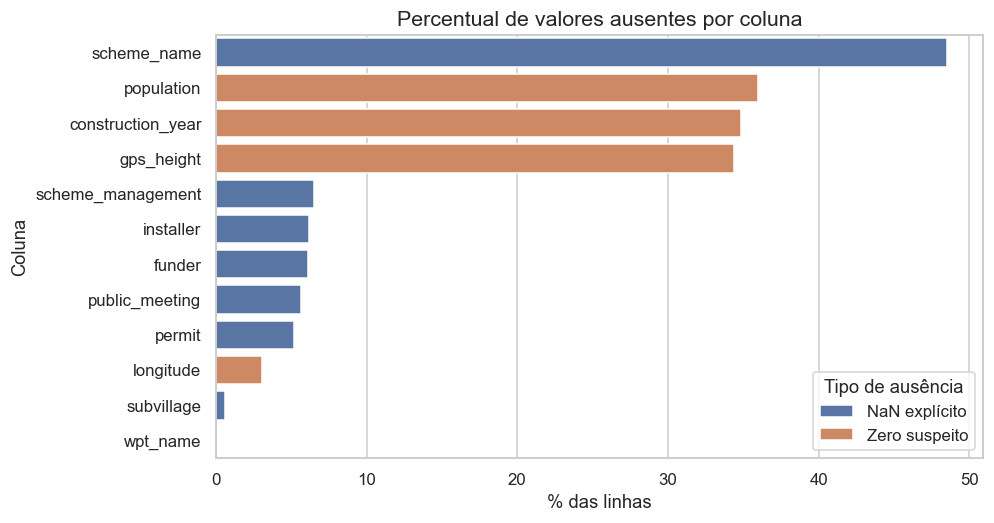

In [16]:
# [IA] Claude Code – gráfico: % de ausência por coluna (NaN explícito e zero suspeito)
pct_nan = (df.isna().mean() * 100)[lambda s: s > 0]
pct_zero = pd.Series({c: (df[c] == 0).mean() * 100
                      for c in ["population", "construction_year", "gps_height", "longitude"]})
graf = pd.concat([
    pd.DataFrame({"coluna": pct_nan.index, "pct": pct_nan.values, "tipo": "NaN explícito"}),
    pd.DataFrame({"coluna": pct_zero.index, "pct": pct_zero.values, "tipo": "Zero suspeito"}),
]).sort_values("pct", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=graf, y="coluna", x="pct", hue="tipo", dodge=False, ax=ax)
ax.set_title("Percentual de valores ausentes por coluna")
ax.set_xlabel("% das linhas")
ax.set_ylabel("Coluna")
ax.legend(title="Tipo de ausência")
salvar(fig, "02_ausencia_por_coluna")
plt.show()

### 2.5 Indicadores de ausência e padrões

Uma coluna 0/1 por variável (1 = ausente, contando `NaN` e os códigos suspeitos acima). Usada só para estudar o mecanismo.

In [17]:
# [IA] Claude Code + Gemini – indicadores de ausência (1 = ausente, com coluna glossario)
ausente = pd.DataFrame({
    "population": df["population"] == 0,
    "construction_year": df["construction_year"] == 0,
    "gps_height": df["gps_height"] == 0,
    "longitude": df["longitude"] == 0,
    "scheme_name": df["scheme_name"].isna(),
    "scheme_management": df["scheme_management"].isna(),
    "installer": df["installer"].isna() | df["installer"].isin(["0", "-"]),
    "funder": df["funder"].isna() | df["funder"].isin(["0", "-"]),
    "public_meeting": df["public_meeting"].isna(),
    "permit": df["permit"].isna(),
}).astype(int)
pct_aus = ausente.mean().mul(100).round(2).sort_values(ascending=False)
com_titulo(
    pd.DataFrame({"glossario": [glossario(c) for c in pct_aus.index], "pct_ausente": pct_aus}).style.format({"pct_ausente": "{:.2f}%"}),
    "Tabela 2.5 — Percentual de ausência por indicador (NaN + zeros/códigos suspeitos)"
)

,glossario,pct_ausente
scheme_name,Quem opera o ponto d'água / nome do esquema,48.50%
population,População ao redor do poço,35.99%
construction_year,Ano de construção do ponto d'água,34.86%
gps_height,Altitude do poço (unidade a confirmar),34.41%
installer,Organização que instalou o poço,7.47%
funder,Quem financiou o poço,7.43%
scheme_management,Quem opera o ponto d'água,6.53%
public_meeting,Verdadeiro/Falso (significado a confirmar),5.61%
permit,Se o ponto d'água tem permissão (licença),5.14%
longitude,Coordenada GPS (longitude),3.05%


#### 2.5.1 Coocorrência de ausência entre colunas

Calcula a correlação entre os indicadores binários de ausência (0/1) das colunas, para verificar se os valores faltantes ocorrem em conjunto nas mesmas linhas.

> **Como ler:** Cada quadrado é a correlação (de -1 a 1) entre os indicadores de ausência de duas colunas. Perto de 1: ausentes nas mesmas linhas. Vermelho é positivo e azul é negativo.

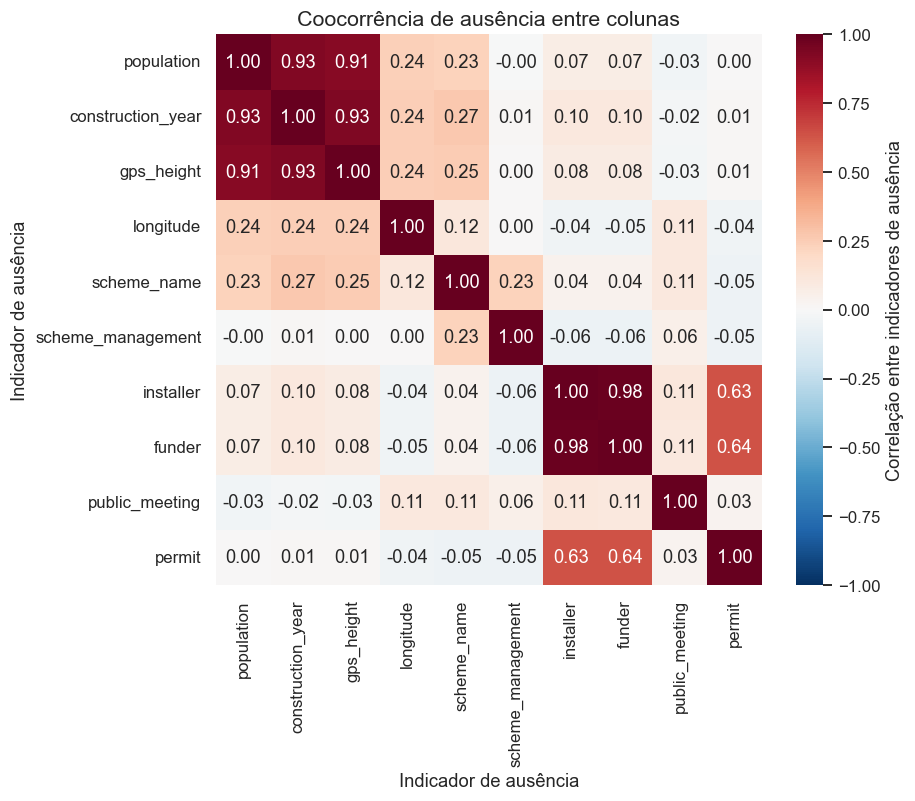

In [18]:
# [IA] Claude Code – gráfico: a ausência de uma coluna acompanha a de outra? (correlação entre os indicadores)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(ausente.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação entre indicadores de ausência"}, ax=ax)
ax.set_title("Coocorrência de ausência entre colunas")
ax.set_xlabel("Indicador de ausência")
ax.set_ylabel("Indicador de ausência")
salvar(fig, "02_coocorrencia_ausencia")
plt.show()

#### 2.5.2 Ausência por região (%)

Agrupa os indicadores de ausência por região geográfica (`region`) para exibir o percentual de dados faltantes de cada coluna dentro de cada região.

> **Como ler:** As linhas são as regiões e as colunas são as variáveis. O número é o percentual de linhas ausentes naquela região; quanto mais escuro, maior.

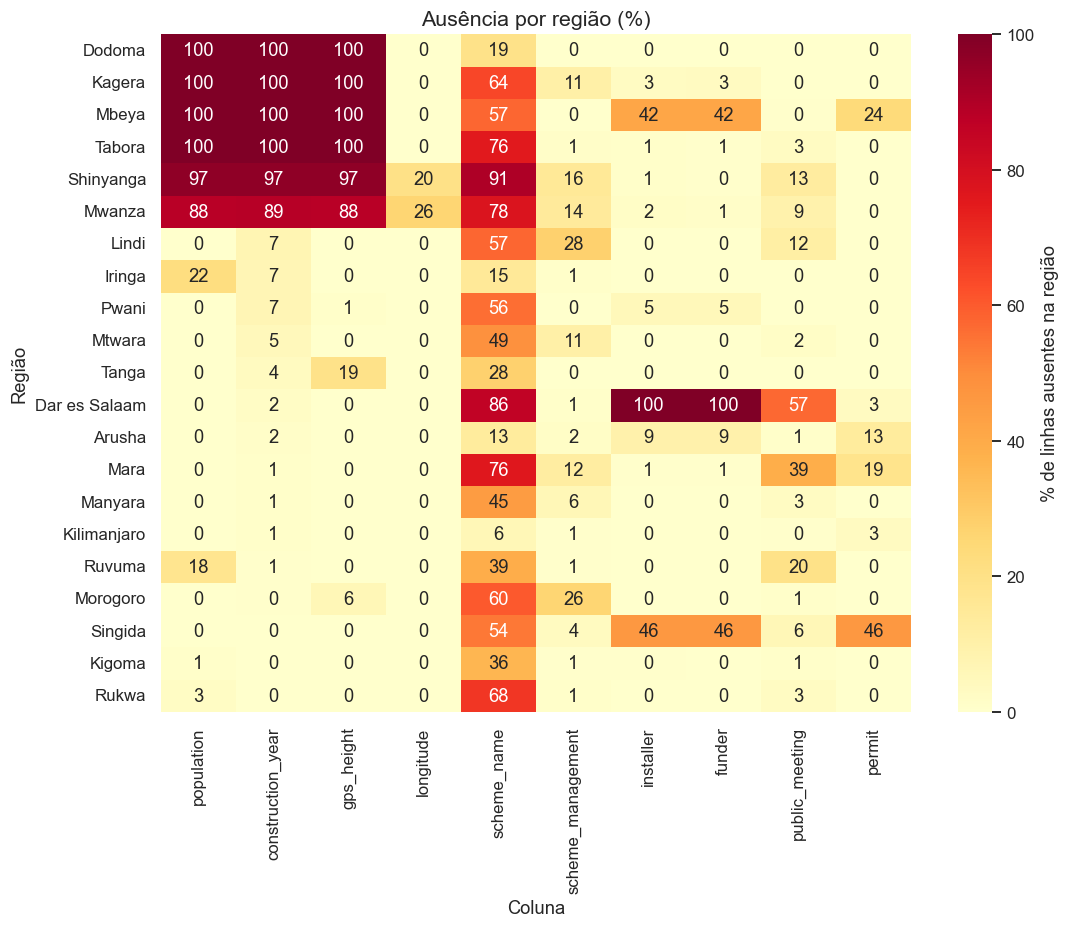

In [19]:
# [IA] Claude Code – gráfico: % de ausência de cada coluna dentro de cada região
por_regiao = ausente.groupby(df["region"]).mean().mul(100)
por_regiao = por_regiao.sort_values("construction_year", ascending=False)

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(por_regiao, annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "% de linhas ausentes na região"}, ax=ax)
ax.set_title("Ausência por região (%)")
ax.set_xlabel("Coluna")
ax.set_ylabel("Região")
salvar(fig, "02_ausencia_por_regiao")
plt.show()

#### 2.5.3 Ausência por ano de registro (`date_recorded`)

Agrupa os registros e os indicadores de ausência pelo ano de coleta (`date_recorded`) para verificar como a taxa de ausência varia ao longo dos anos.

> **Como ler:** Cada linha é um ano de registro (`date_recorded`) e o número é o percentual de ausência de cada coluna naquele ano.

In [20]:
# [IA] Claude Code – % de ausência por ano de registro (date_recorded)
ano_registro = pd.to_datetime(df["date_recorded"]).dt.year
display(com_titulo(ano_registro.value_counts().sort_index().rename("n_linhas").to_frame().T, "Tabela 2.5.3a — Total de registros por ano de coleta"))
com_titulo(
    ausente.groupby(ano_registro).mean().mul(100).round(1).style.background_gradient(
        cmap="YlOrRd", vmin=0, vmax=100, axis=None).format("{:.1f}%"),
    "Tabela 2.5.3b — Percentual de ausência por ano de registro (%)"
)

date_recorded,2002,2004,2011,2012,2013
n_linhas,1,30,28674,6424,24271


,population,construction_year,gps_height,longitude,scheme_name,scheme_management,installer,funder,public_meeting,permit
date_recorded,,,,,,,,,,
2002,100.0%,100.0%,100.0%,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%
2004,36.7%,43.3%,36.7%,0.0%,63.3%,13.3%,6.7%,6.7%,20.0%,3.3%
2011,48.3%,46.5%,46.8%,2.0%,47.5%,6.3%,7.8%,7.8%,1.2%,3.9%
2012,79.8%,80.0%,79.8%,7.1%,82.4%,11.5%,0.7%,0.6%,12.6%,2.6%
2013,9.9%,9.1%,7.7%,3.3%,40.7%,5.5%,8.8%,8.8%,8.9%,7.3%


#### 2.5.4 Ausência por situação do ponto d'água (`status_group`)

Cruza os indicadores de ausência com a variável-alvo (`status_group`) para verificar a taxa de ausência em cada classe e a distribuição das classes com/sem `construction_year`.

> **Como ler:** Primeira tabela: para cada situação do ponto d'água (linhas), o percentual de ausência de cada coluna. Segunda tabela: para quem tem ou não `construction_year`, a distribuição da situação (cada linha soma 100%).

In [21]:
# [IA] Claude Code – a ausência está associada à classe? (% de ausência dentro de cada status)
display(com_titulo(
    ausente.groupby(df[COL_ALVO]).mean().mul(100).round(1).reindex(STATUS_ORDEM).style.background_gradient(
        cmap="YlOrRd", vmin=0, vmax=100, axis=None).format("{:.1f}%"),
    "Tabela 2.5.4a — Percentual de ausência dentro de cada classe de status_group (%)"
))

# e o contrário: distribuição da classe entre linhas com e sem construction_year
com_titulo(
    pd.crosstab(ausente["construction_year"].map({0: "informado", 1: "ausente (0)"}),
                df[COL_ALVO], normalize="index").mul(100).round(1)[STATUS_ORDEM].style.background_gradient(
        cmap="Blues", vmin=0, vmax=100, axis=None).format("{:.1f}%"),
    "Tabela 2.5.4b — Distribuição de status_group com e sem construction_year (%)"
)

,population,construction_year,gps_height,longitude,scheme_name,scheme_management,installer,funder,public_meeting,permit
status_group,,,,,,,,,,
functional,34.9%,32.7%,32.5%,2.7%,46.2%,5.8%,7.6%,7.5%,5.2%,5.2%
functional needs repair,41.1%,41.4%,40.8%,8.9%,47.1%,5.2%,10.3%,10.2%,3.6%,6.9%
non functional,36.5%,36.7%,36.0%,2.4%,52.0%,7.8%,6.8%,6.8%,6.6%,4.7%


status_group,functional,functional needs repair,non functional
construction_year,,,
ausente (0),51.0%,8.6%,40.4%
informado,56.1%,6.5%,37.4%


### ✅ [AUTORAL] 2.6 Mecanismo de ausência e tratamento proposto

> Olhando tanto os `NaN` explícitos quanto os zeros disfarçados, dá para ver que a ausência não acontece de forma aleatória (o que descarta MCAR). O principal bloco de zeros suspeitos junta `population` (36,0%), `construction_year` (34,9%) e `gps_height` (34,4%), com coocorrência de 0,91 a 0,93 entre si. Esses zeros ficam concentrados em 6 regiões da Tanzânia (Dodoma, Kagera, Mbeya, Tabora, Shinyanga e Mwanza), variando de 88,6% a 100% de ausência durante as coletas de 2011 a 2013, enquanto as outras 15 regiões ficam abaixo de 7,3%. Sem precisar entrar na causa administrativa externa, o fato de a ausência depender diretamente da variável observável `region` mostra um caso de MAR (Missing At Random), que é tratável conforme visto na Aula 09.

> Não faz sentido apagar esses registros do dataset, porque isso cortaria cerca de um terço dos dados e sumiria com quase 100% de 6 regiões inteiras, gerando um viés pesado. Para as numéricas com zeros suspeitos (`population`, `construction_year`, `gps_height` e as coordenadas zeradas de `longitude` e `latitude`), a decisão é transformar esses zeros em `NaN` e imputar usando a mediana agrupada por variável geográfica observável (escolhendo mediana em vez de média, como visto na Aula 09, por ser menos sensível a outliers).

> Um detalhe importante dessa imputação é fazer em cascata com fallback: como 4 regiões (Dodoma, Kagera, Mbeya e Tabora) têm 0 valores válidos em `construction_year`, `gps_height` e `population`, agrupar só por `region` ou `lga` deixaria essas regiões ainda vazias. Como todas as 9 bacias hidrográficas (`basin`) têm pelo menos 988 registros válidos nessas colunas (e todas as 21 regiões têm ao menos 805 válidos para `longitude` e `latitude`), primeiro tenta-se preencher pela mediana de `lga`/`region` e, onde o grupo não tiver valor válido, aplica-se o fallback pela mediana de `basin`. Na etapa do classificador, essas medianas precisam ser calculadas só no treino para não gerar data leakage (Aula 26).

> Para o restante das colunas com ausência ou excesso de zeros, as decisões são: preencher os `NaN` (e os códigos `'0'` e `'-'`) das categóricas `scheme_management`, `installer`, `funder`, `public_meeting`, `permit` e `subvillage` com a categoria `"desconhecido"`, para o `RandomForestClassifier` tratar a ausência como um grupo próprio sem distorcer as categorias reais nem vazar informação; descartar `num_private` (98,7% zeros e sem descrição oficial) e `scheme_name` (48,5% ausente, alta cardinalidade e sobreposta a `scheme_management`, que continua no dataset); e manter `amount_tsh` com o valor `0` (70,0% zeros), porque imputar 70% de uma coluna distorceria a distribuição e a diferença entre `amount_tsh == 0` e `> 0` separa bastante o `status_group` (45,4% contra 22,2% de `non functional`), mesmo misturando falta de medição com pontos sem carga.

<a id="secao-5"></a>

## 3. Análise Distribucional

Distribuição da classe, das variáveis quantitativas e das qualitativas.

Nos gráficos das quantitativas, os zeros suspeitos da seção 2 são **escondidos apenas para a visualização** (cópia `viz`), para não deformar o eixo. `df` continua intacto.

### 3.1 Distribuição da variável-alvo (`status_group`)

Exibe a contagem absoluta e a proporção percentual de cada uma das três classes da variável-alvo (`status_group`).

> **Como ler:** Cada barra é uma situação do ponto d'água. A altura é a contagem, e o rótulo mostra a contagem e o percentual do total.

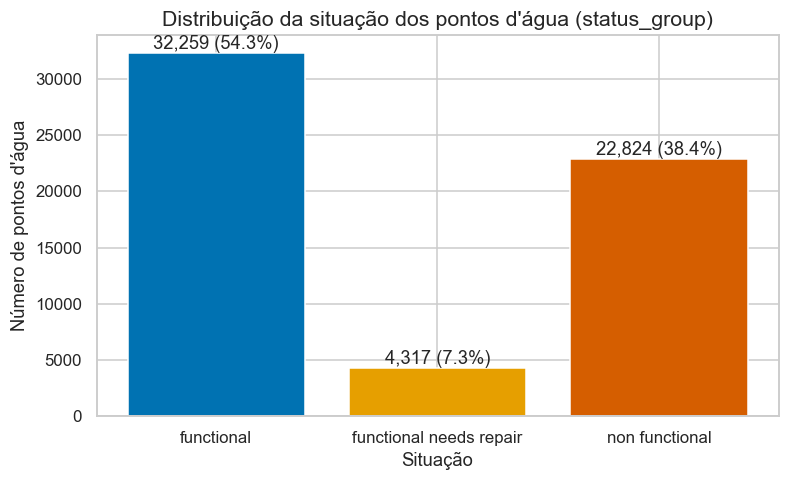

In [22]:
# [IA] Claude Code – gráfico: distribuição da classe
contagem = df[COL_ALVO].value_counts().reindex(STATUS_ORDEM)

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(contagem.index, contagem.values, color=[STATUS_CORES[s] for s in contagem.index])
ax.bar_label(barras, labels=[f"{v:,} ({v / len(df):.1%})" for v in contagem.values])
ax.set_title("Distribuição da situação dos pontos d'água (status_group)")
ax.set_xlabel("Situação")
ax.set_ylabel("Número de pontos d'água")
salvar(fig, "03_distribuicao_classe")
plt.show()

### 3.2 Estatísticas descritivas das quantitativas

Apresenta as estatísticas descritivas (contagem válida, média, desvio-padrão, quartis, mínimo, máximo e assimetria) das variáveis quantitativas, ocultando temporariamente os zeros suspeitos apenas para visualização.

> **Como ler:** `count` é o número de valores válidos; `mean` e `std` são a média e o desvio-padrão; `25%`, `50%` (mediana) e `75%` são os quartis; `assimetria` é vista na Aula 10; `n_ausentes_na_viz` é quanto foi ocultado (zeros suspeitos).

In [23]:
# [IA] Claude Code + Gemini – cópia só para visualização e estatísticas descritivas (com coluna glossario)
COLS_NUM_VIZ = [c for c in COLS_NUM if c != "num_private"]  # num_private descartada (98,7% zeros, sem descrição)
viz = df[COLS_NUM_VIZ].copy()
for c in ["population", "construction_year", "gps_height"]:
    viz.loc[viz[c] == 0, c] = np.nan
viz.loc[df["longitude"] == 0, ["longitude", "latitude"]] = np.nan

estat = viz.describe().T
estat["assimetria"] = viz.skew()
estat["n_ausentes_na_viz"] = viz.isna().sum()
cols_num_estat = list(estat.columns)
estat.insert(0, "glossario", [glossario(c) for c in estat.index])
com_titulo(estat.style.format("{:,.2f}", subset=cols_num_estat), "Tabela 3.2 — Estatísticas descritivas das variáveis quantitativas (zeros suspeitos ocultos)")

,glossario,count,mean,std,min,25%,50%,75%,max,assimetria,n_ausentes_na_viz
amount_tsh,Total static head: água disponível no ponto (unidade a confirmar),"59,400.00",317.65,"2,997.57",0.00,0.00,0.00,20.00,"350,000.00",57.81,0.00
gps_height,Altitude do poço (unidade a confirmar),"38,962.00","1,018.86",612.57,-90.00,393.00,"1,167.00","1,498.00","2,770.00",-0.20,"20,438.00"
longitude,Coordenada GPS (longitude),"57,588.00",35.15,2.61,29.61,33.29,35.01,37.23,40.35,-0.13,"1,812.00"
latitude,Coordenada GPS (latitude),"57,588.00",-5.89,2.81,-11.65,-8.64,-5.17,-3.37,-1.00,-0.25,"1,812.00"
population,População ao redor do poço,"38,019.00",281.09,564.69,1.00,40.00,150.00,324.00,"30,500.00",10.99,"21,381.00"
construction_year,Ano de construção do ponto d'água,"38,691.00","1,996.81",12.47,"1,960.00","1,987.00","2,000.00","2,008.00","2,013.00",-0.73,"20,709.00"


### 3.3 Histogramas das variáveis quantitativas

Plota a distribuição de frequência (histogramas) de cada variável quantitativa usando apenas os valores válidos.

> **Como ler:** Cada gráfico mostra quantas linhas caem em cada faixa de valores (eixo x). Nas variáveis muito esticadas o eixo é logarítmico e só entram os valores acima de zero.

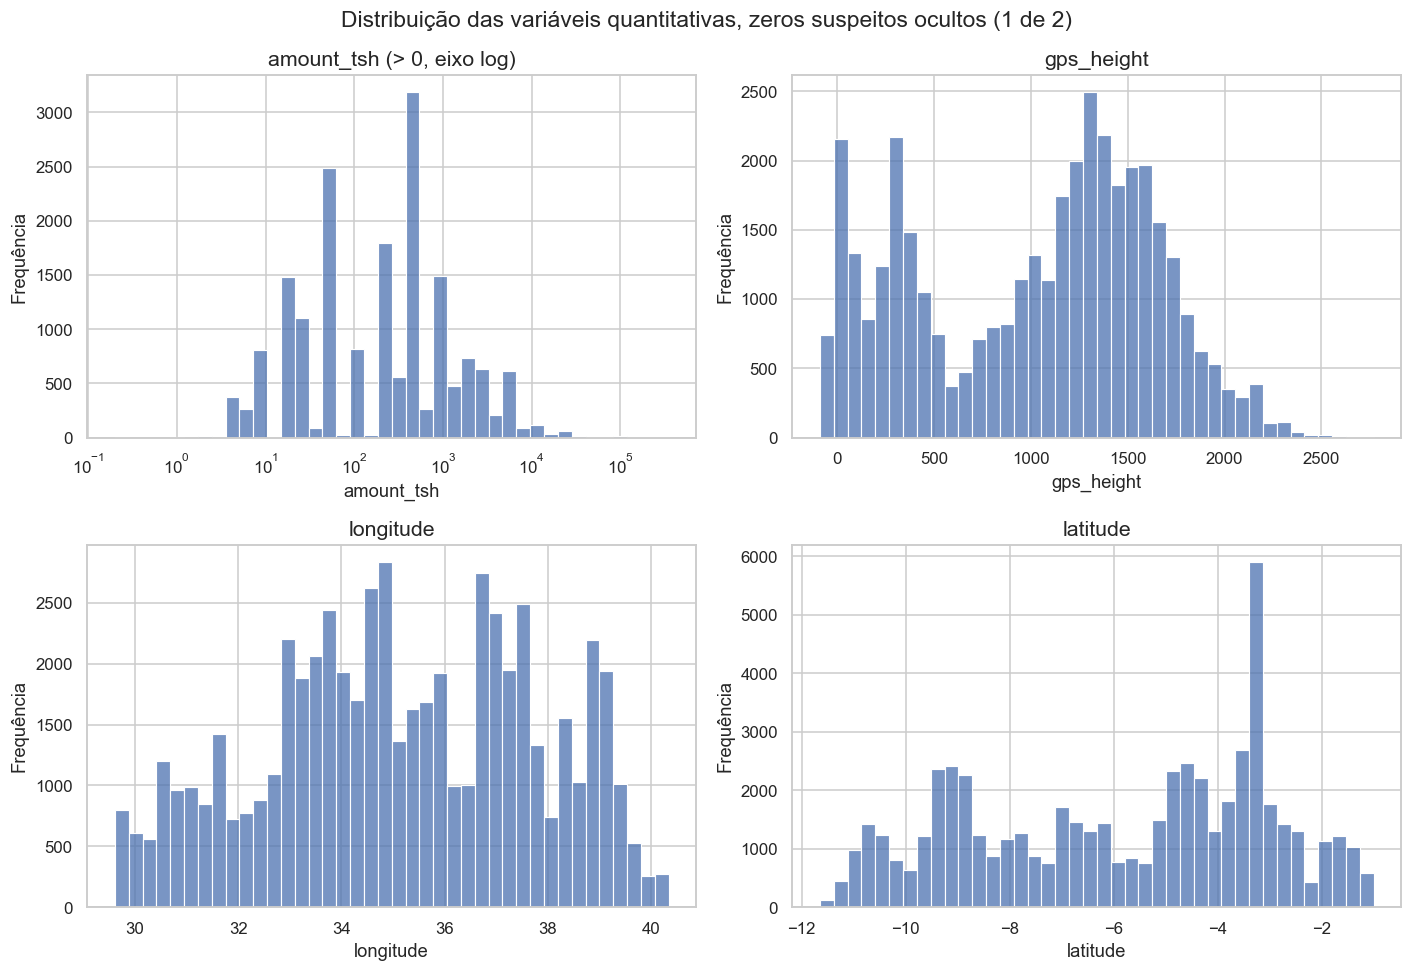

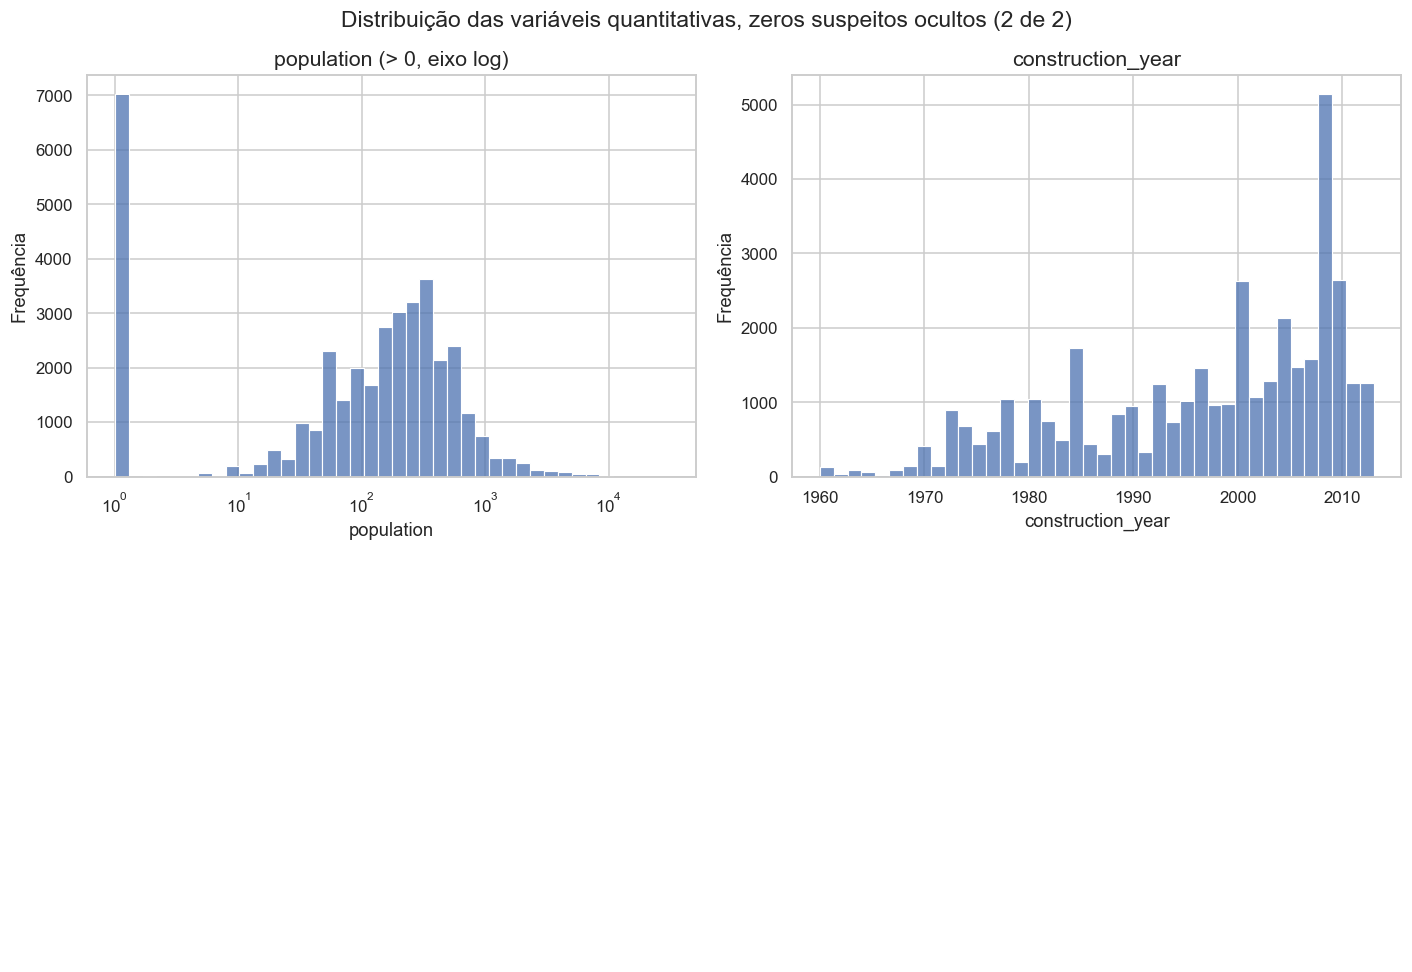

In [24]:
# [IA] Claude Code – gráfico: histogramas das quantitativas (duas figuras, para ficarem maiores)
COLS_LOG = ["amount_tsh", "population"]  # muito assimétricas: só valores > 0, eixo em log


def histogramas(colunas, nome, parte):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, col in zip(axes.flat, colunas):
        dados = viz[col].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            dados = dados[dados > 0]
        sns.histplot(dados, bins=40, log_scale=usar_log, ax=ax, color="#4C72B0")
        ax.set_title(col + (" (> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel(col)
        ax.set_ylabel("Frequência")
    for ax in axes.flat[len(colunas):]:
        ax.axis("off")
    fig.suptitle(f"Distribuição das variáveis quantitativas, zeros suspeitos ocultos ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


histogramas(COLS_NUM_VIZ[:4], "03_histogramas_quantitativas_1", 1)
histogramas(COLS_NUM_VIZ[4:], "03_histogramas_quantitativas_2", 2)

### 3.4 Frequência das qualitativas de baixa cardinalidade (versões generalizadas)

Plota a contagem de registros por categoria para as 12 variáveis qualitativas não redundantes de baixa cardinalidade (versões generalizadas escolhidas na Seção 1.6, sem `recorded_by` nem códigos repetidos).

> **Como ler:** Cada gráfico é uma coluna e cada barra é uma categoria, da mais frequente para a menos frequente. `(ausente)` marca os `NaN`.

12 colunas (versões generalizadas): ['quantity', 'extraction_type_class', 'waterpoint_type_group', 'payment_type', 'quality_group', 'source_class', 'management_group', 'scheme_management', 'basin', 'region', 'public_meeting', 'permit']


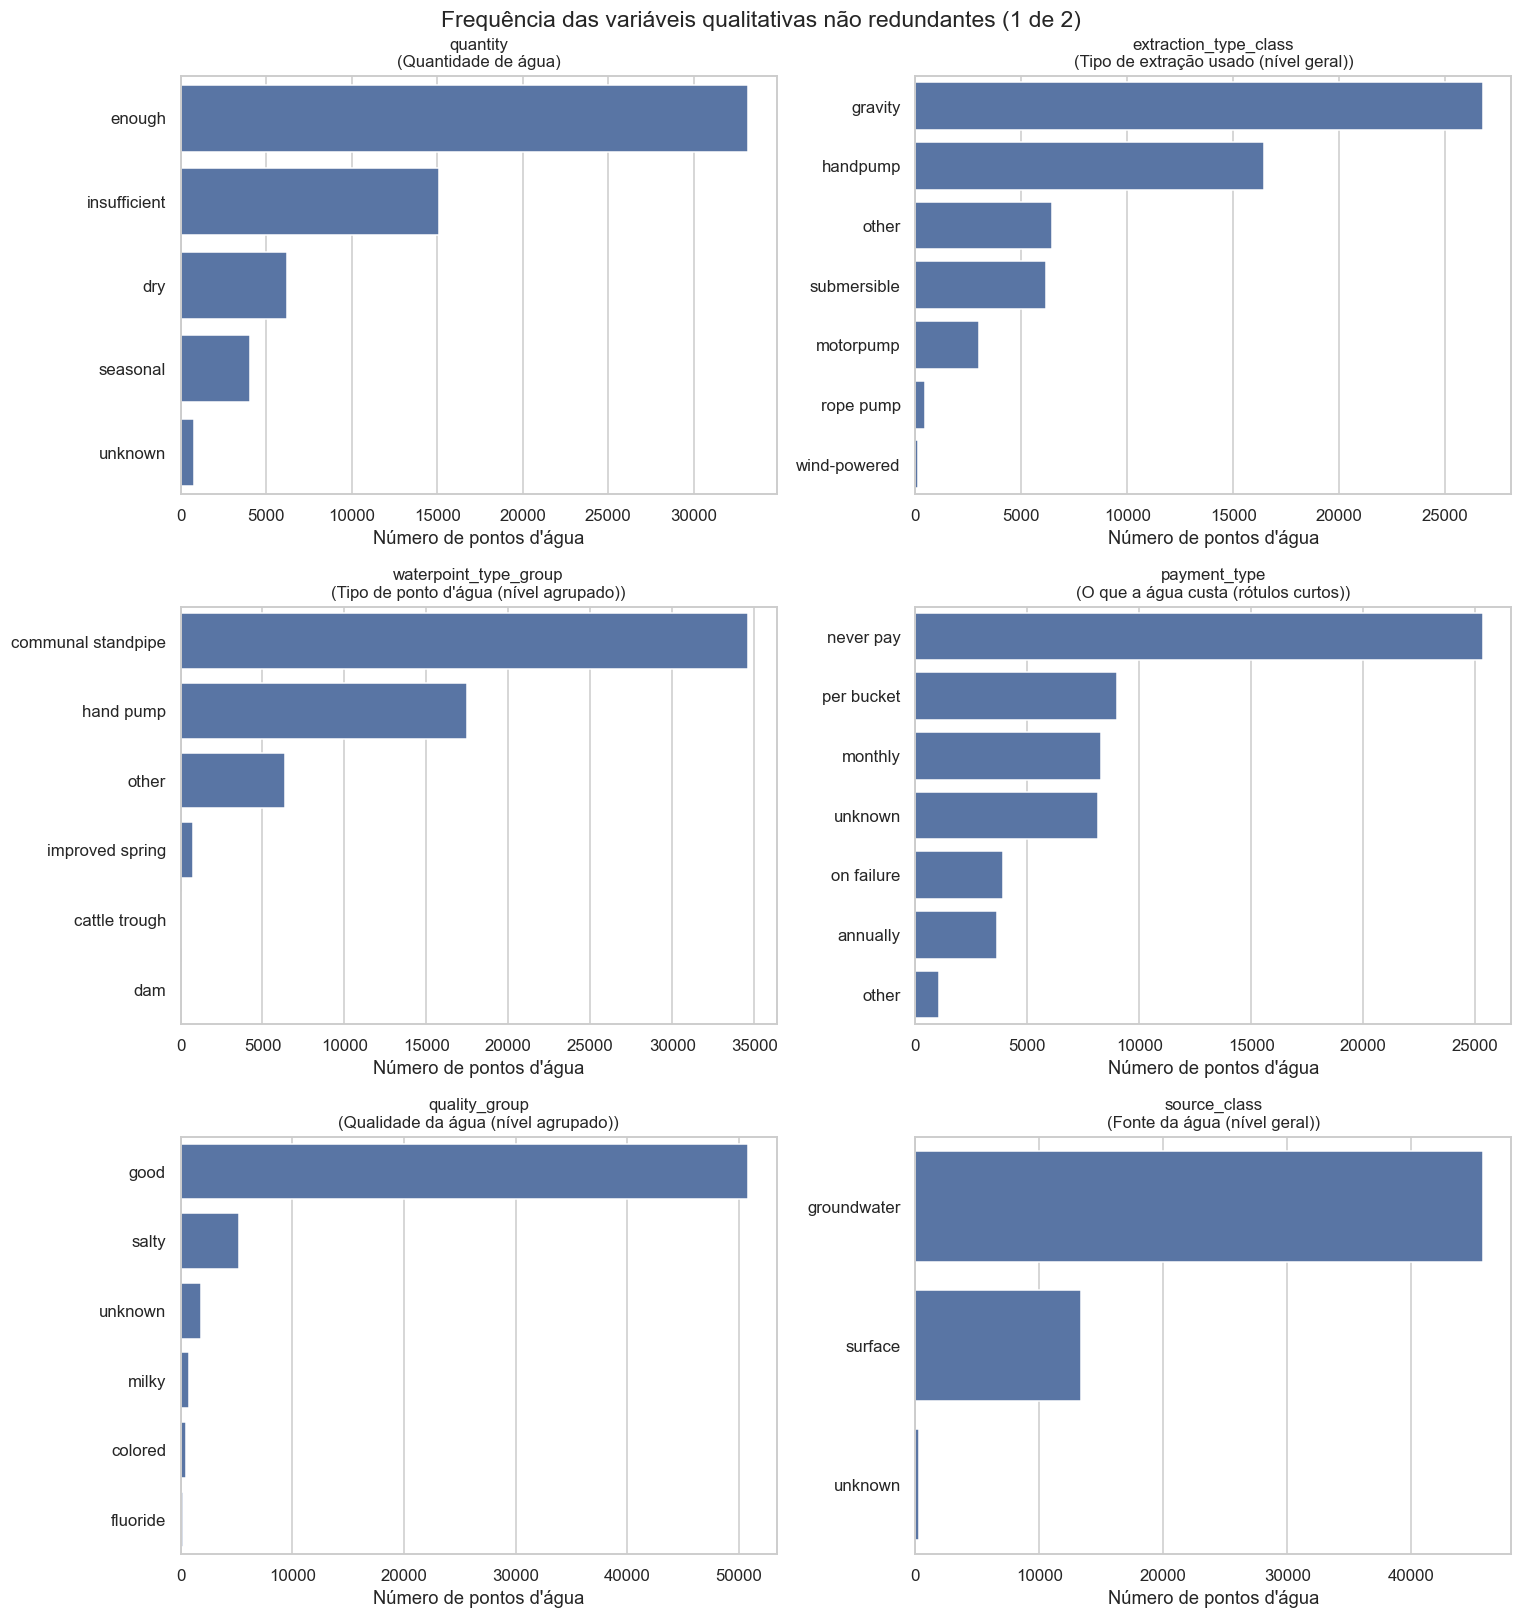

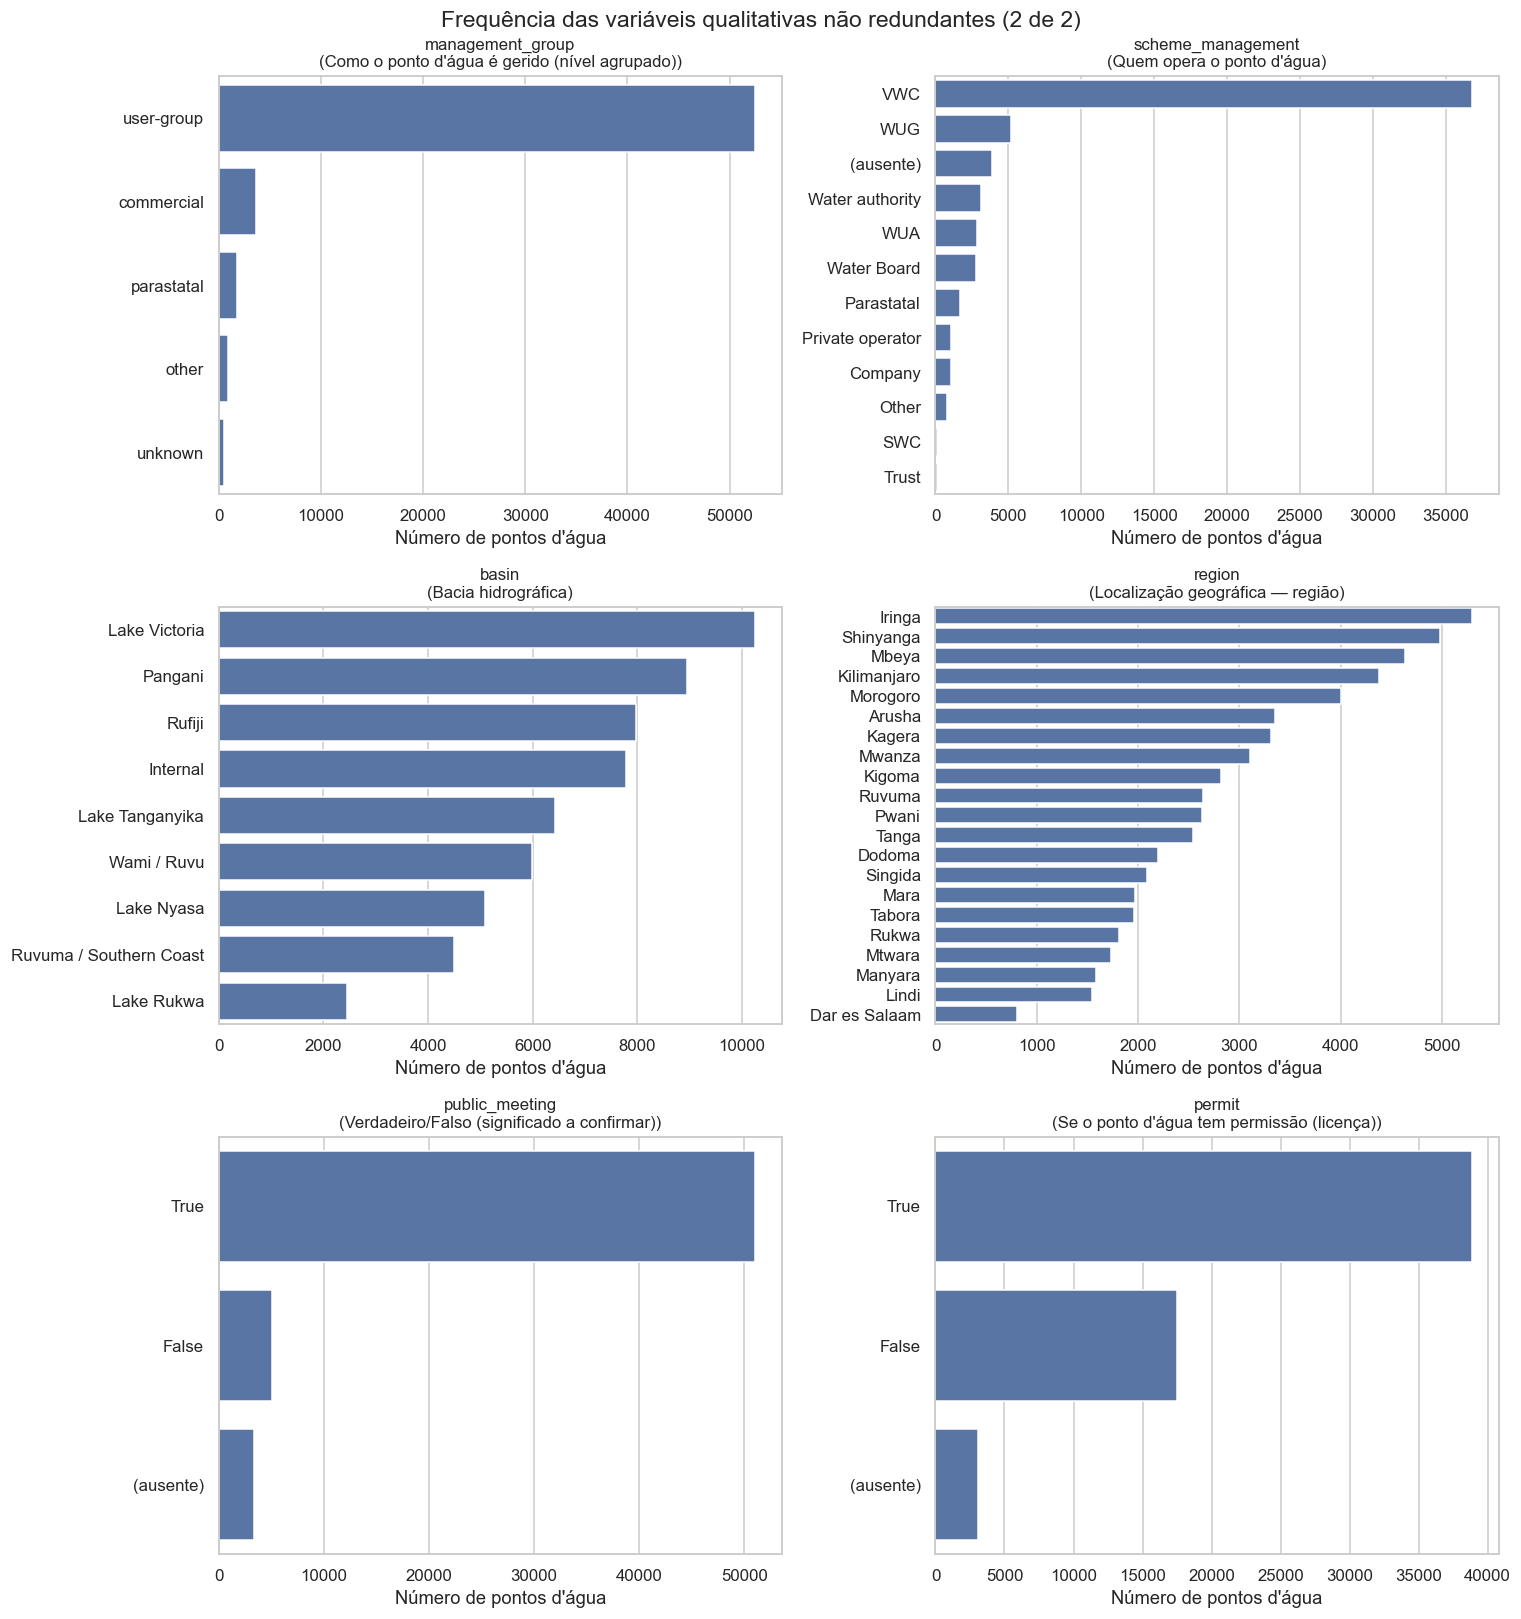

In [25]:
# [IA] Claude Code + Gemini – gráfico: frequência das 12 qualitativas não redundantes (versões generalizadas), 6 por figura
cats_baixa = [
    "quantity", "extraction_type_class", "waterpoint_type_group", "payment_type",
    "quality_group", "source_class", "management_group", "scheme_management",
    "basin", "region", "public_meeting", "permit",
]
print(len(cats_baixa), "colunas (versões generalizadas):", cats_baixa)

POR_FIGURA = 6
n_partes = int(np.ceil(len(cats_baixa) / POR_FIGURA))
for parte, inicio in enumerate(range(0, len(cats_baixa), POR_FIGURA), start=1):
    grupo = cats_baixa[inicio:inicio + POR_FIGURA]
    fig, axes = plt.subplots(3, 2, figsize=(14, 15))
    for ax, col in zip(axes.flat, grupo):
        valores = df[col].astype("string").fillna("(ausente)")
        ordem = valores.value_counts().index
        sns.countplot(y=valores, order=ordem, ax=ax, color="#4C72B0")
        ax.set_title(f"{col}\n({glossario(col)})", fontsize=11)
        ax.set_xlabel("Número de pontos d'água")
        ax.set_ylabel("")
    for ax in axes.flat[len(grupo):]:
        ax.axis("off")
    fig.suptitle(f"Frequência das variáveis qualitativas não redundantes ({parte} de {n_partes})", fontsize=15)
    fig.tight_layout()
    salvar(fig, f"03_frequencias_qualitativas_{parte}")
    plt.show()

### 3.5 Top 15 categorias das qualitativas de alta cardinalidade

Exibe as 15 categorias mais frequentes das colunas qualitativas de alta cardinalidade (`funder`, `installer` e `lga`).

> **Como ler:** Para cada coluna com milhares de valores, as 15 categorias com mais pontos d'água. O título mostra quantas categorias existem no total.

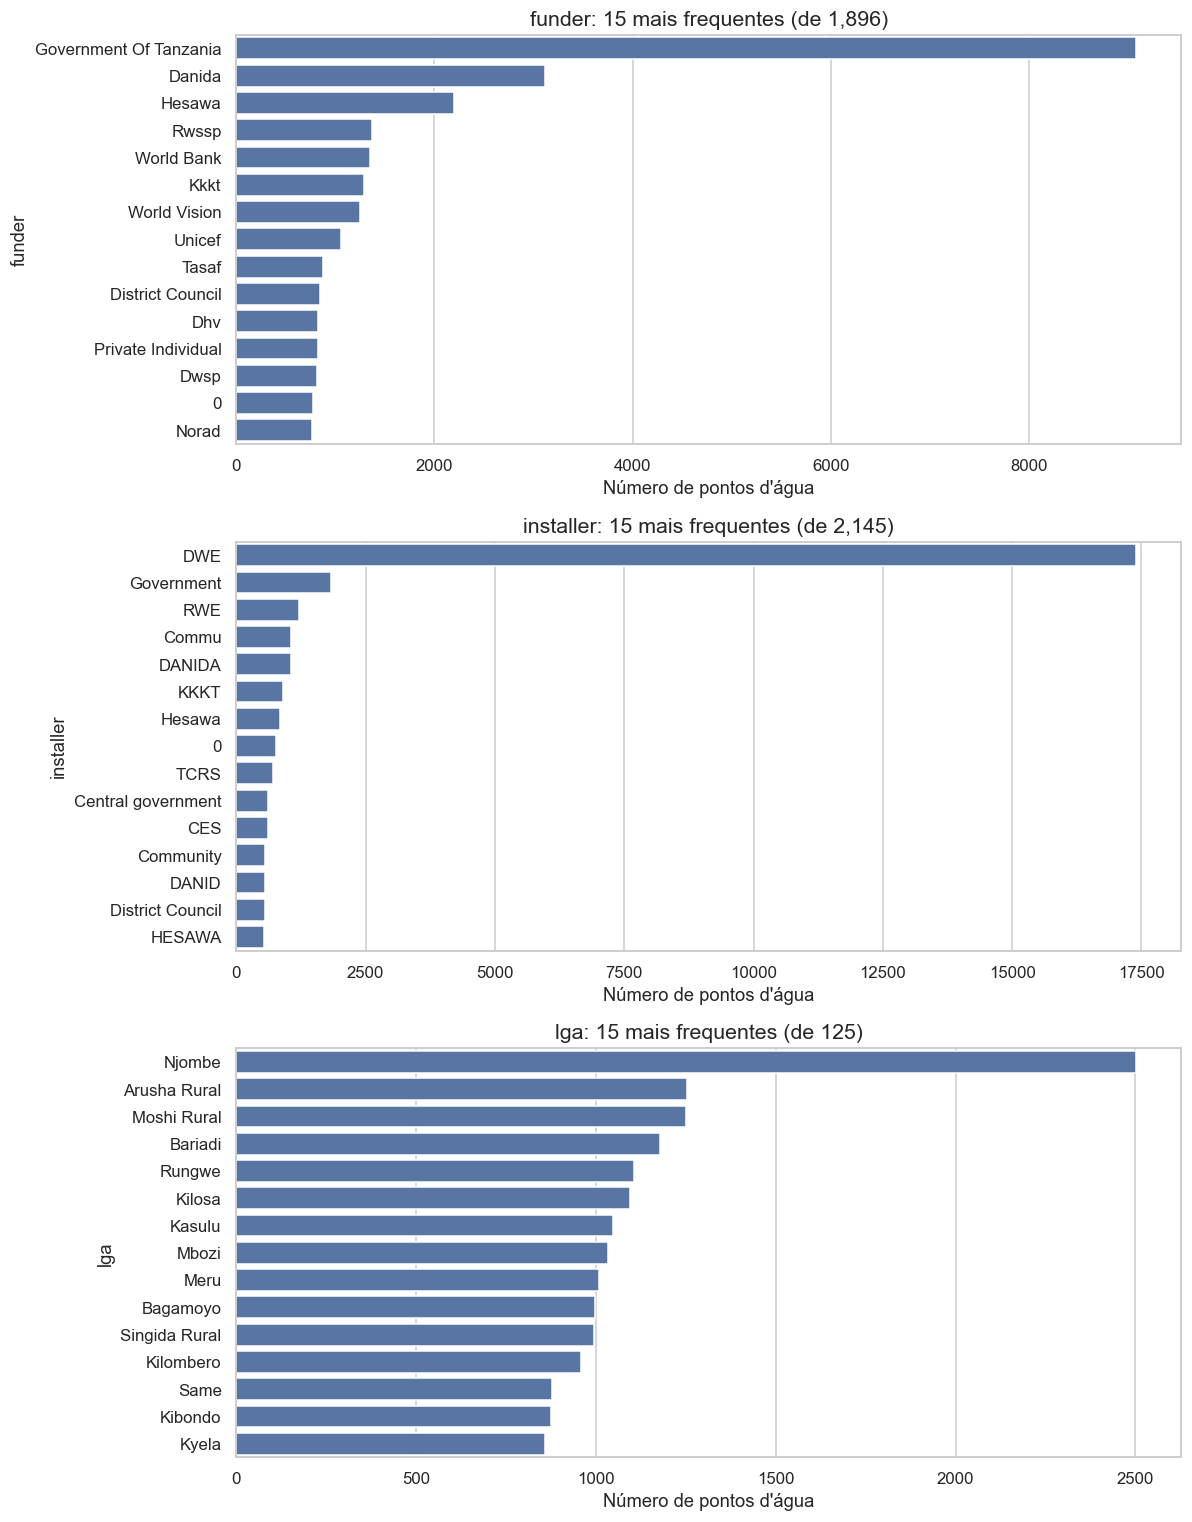

In [26]:
# [IA] Claude Code – gráfico: as 15 categorias mais frequentes das colunas de alta cardinalidade
fig, axes = plt.subplots(3, 1, figsize=(11, 14))
for ax, col in zip(axes, ["funder", "installer", "lga"]):
    top = df[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax, color="#4C72B0")
    ax.set_title(f"{col}: 15 mais frequentes (de {df[col].nunique():,})")
    ax.set_xlabel("Número de pontos d'água")
    ax.set_ylabel(col)
fig.tight_layout()
salvar(fig, "03_top_alta_cardinalidade")
plt.show()

### 3.6 Registros por ano (`date_recorded`)

Mostra a distribuição temporal do volume de pontos d'água registrados em cada ano de `date_recorded`.

> **Como ler:** Cada barra é um ano de registro (`date_recorded`) e a altura é o número de linhas registradas nele.

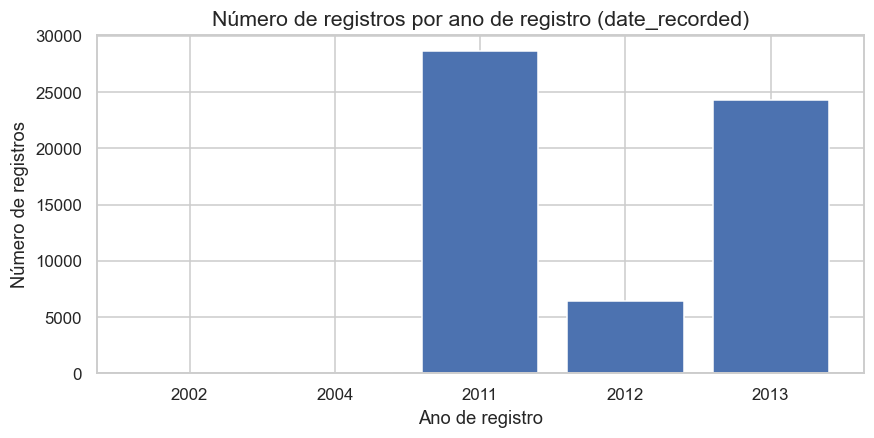

In [27]:
# [IA] Claude Code – gráfico: registros por ano (date_recorded)
ano_registro = pd.to_datetime(df["date_recorded"]).dt.year
contagem_ano = ano_registro.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(contagem_ano.index.astype(str), contagem_ano.values, color="#4C72B0")
ax.set_title("Número de registros por ano de registro (date_recorded)")
ax.set_xlabel("Ano de registro")
ax.set_ylabel("Número de registros")
salvar(fig, "03_registros_por_ano")
plt.show()

### ✅ [AUTORAL] 3.7 Interpretação — Análise Distribucional

> A distribuição da variável-alvo (`status_group`) é desbalanceada entre as três classes: `functional` tem 54,3% dos registros (32.259), `non functional` tem 38,4% (22.824) e `functional needs repair` tem apenas 7,3% (4.317), sendo a classe minoritária. Por causa disso, na etapa posterior do classificador não vamos olhar só a acurácia geral, mas também precisão, recall e F1 por classe (Aula 26).

> Nas variáveis quantitativas (Tabela 3.2 e Histogramas 3.3, seguindo os critérios de assimetria da Aula 10), `amount_tsh` (assimetria 57,81) e `population` (10,99) têm assimetria alta à direita por causa da cauda longa de valores extremos, o que reforça usar mediana em vez de média. Já `construction_year` (−0,73) tem assimetria moderada à esquerda (mais registros em anos recentes), enquanto `gps_height` (−0,20), `longitude` (−0,13) e `latitude` (−0,25) ficam com assimetria razoável, abaixo de 0,5 em módulo.

> Olhando `date_recorded`, 99,95% dos registros se concentram em 2011, 2012 e 2013. Os outros 0,05% ficam espalhados de forma residual em 2002 e 2004, somando apenas 31 registros (justamente onde estão todas as 9 linhas com idade negativa, com `construction_year > date_recorded`), então esses 31 registros serão cortados na Seção 6.

> Entre as qualitativas, o maior instalador da Tanzânia é o DWE (District Water Engineer), com 31,22% dos registros válidos (29,30% do total) em `installer`. O maior financiador (`funder`) é o próprio governo da Tanzânia (`Government Of Tanzania`), e a predominância de `never pay` (42,7%) em `payment_type` também reforça que a distribuição de água tem forte esforço público. Nas outras qualitativas de baixa cardinalidade (Seção 3.4), também há bastante concentração em poucas categorias: `management_group` tem 88,4% em `user-group`, `quality_group` tem 85,6% em `good`, `source_class` tem 77,1% em `groundwater`, `quantity` tem 55,9% em `enough` (e 25,5% em `insufficient`) e `extraction_type_class` reúne 45,1% em `gravity` e 27,7% em `handpump`.

<a id="secao-6"></a>

## 4. Análise Relacional (com `status_group`)

Relações entre as quantitativas, de cada variável com a classe e uma visão multivariada. Continua usando a cópia `viz` (zeros suspeitos ocultos) para as quantitativas.

### 4.1 Correlação de Spearman entre quantitativas

Calcula a matriz de correlação de Spearman (relação monotônica) entre todos os pares de variáveis quantitativas válidas.

> **Como ler:** Cada quadrado é a correlação de Spearman (de -1 a 1) entre duas variáveis. Perto de 1: sobem juntas. Perto de -1: uma sobe e a outra desce. Perto de 0: sem relação monotônica. Só metade da matriz é mostrada, porque a outra metade é igual.

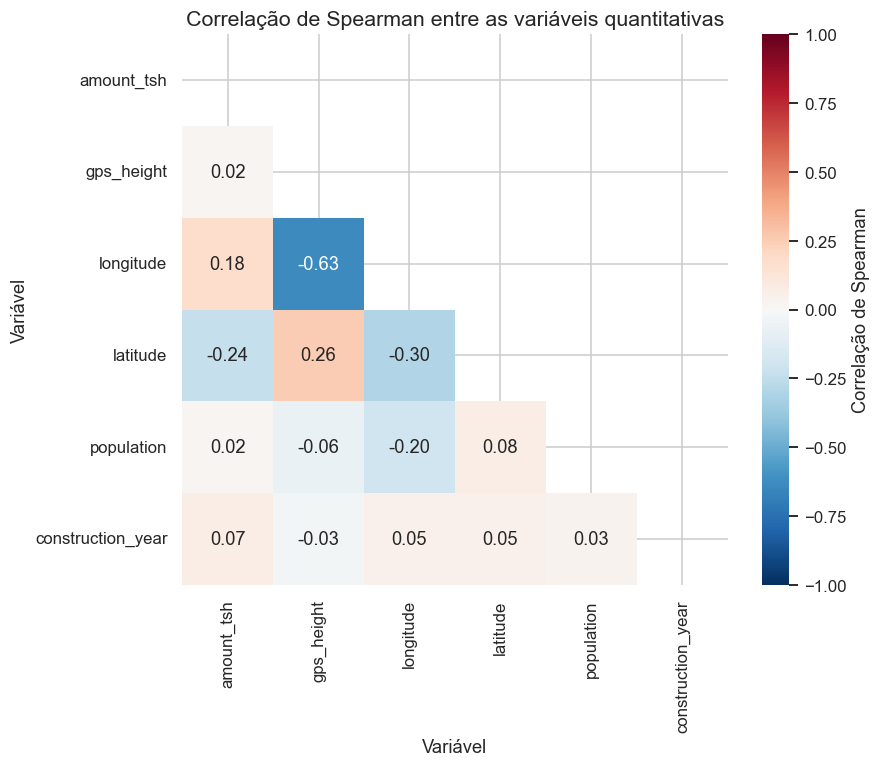

In [28]:
# [IA] Claude Code – gráfico: correlação de Spearman entre as quantitativas (pares com valores válidos)
corr = viz.corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlação de Spearman"}, ax=ax)
ax.set_title("Correlação de Spearman entre as variáveis quantitativas")
ax.set_xlabel("Variável")
ax.set_ylabel("Variável")
salvar(fig, "04_spearman_quantitativas")
plt.show()

In [29]:
# [IA] Claude Code – variável derivada (Aula 26, feature creation): idade do ponto d'água no registro
viz["idade_no_registro"] = pd.to_datetime(df["date_recorded"]).dt.year - viz["construction_year"]
print("Idades negativas (construção depois do registro):", (viz["idade_no_registro"] < 0).sum())
viz["idade_no_registro"].describe().round(1)

Idades negativas (construção depois do registro): 9


count    38691.0
mean        15.4
std         12.5
min         -7.0
25%          5.0
50%         13.0
75%         25.0
max         53.0
Name: idade_no_registro, dtype: float64

### 4.2 Variáveis quantitativas por classe (boxplots)

Compara a distribuição de cada variável quantitativa (incluindo a variável derivada `idade_no_registro`) separadamente entre as três classes de `status_group`.

> **Como ler:** A caixa vai do 1º ao 3º quartil, a linha dentro dela é a mediana, e os pontos são valores fora dos limites do IQR (Aula 10). Cada caixa é uma situação do ponto d'água.

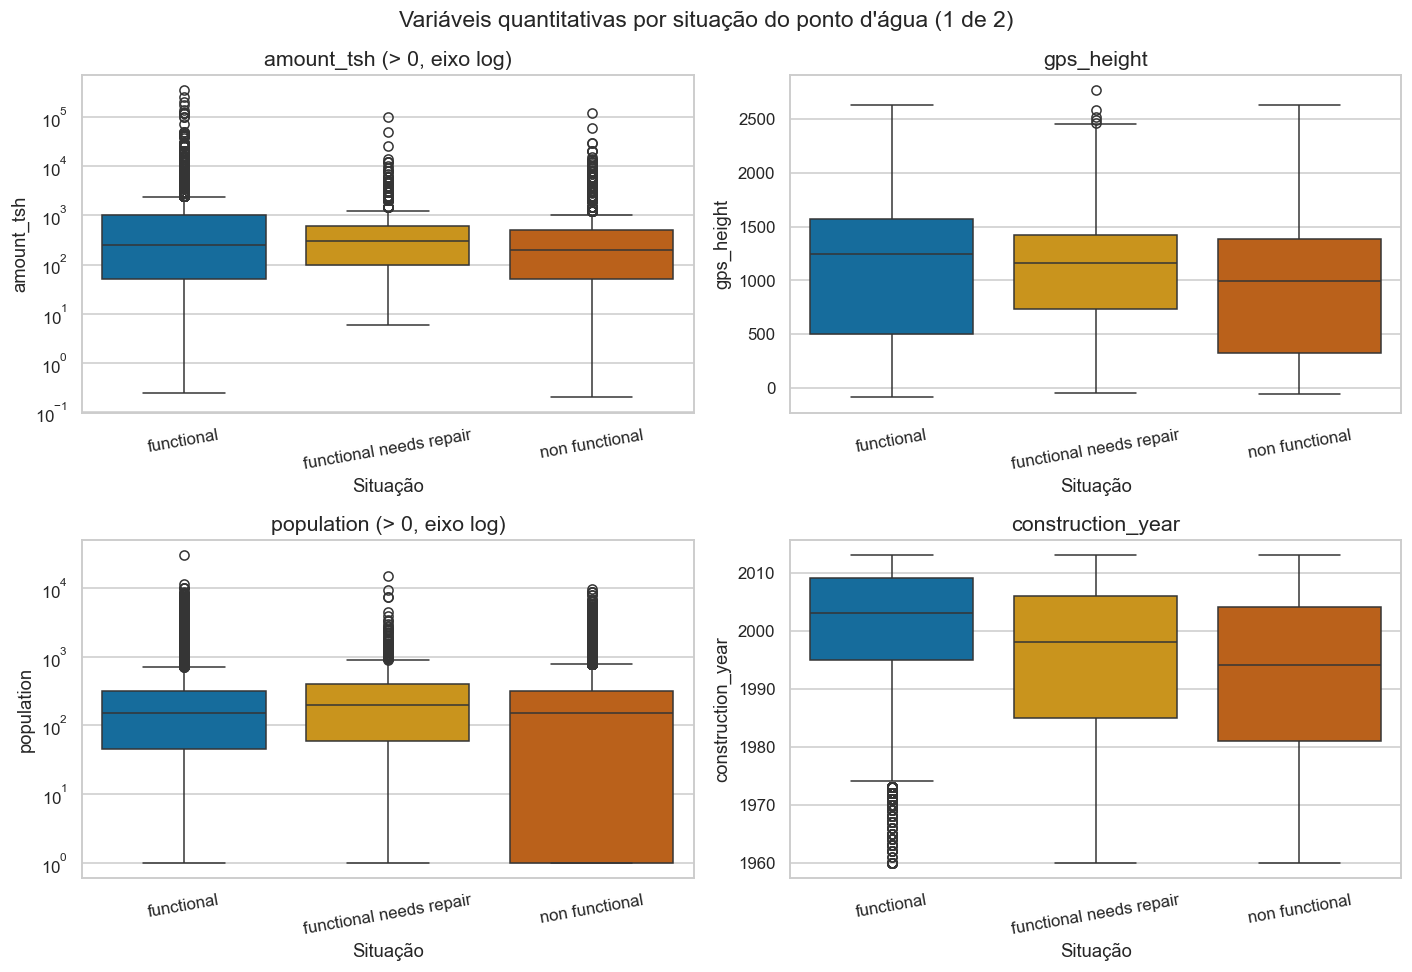

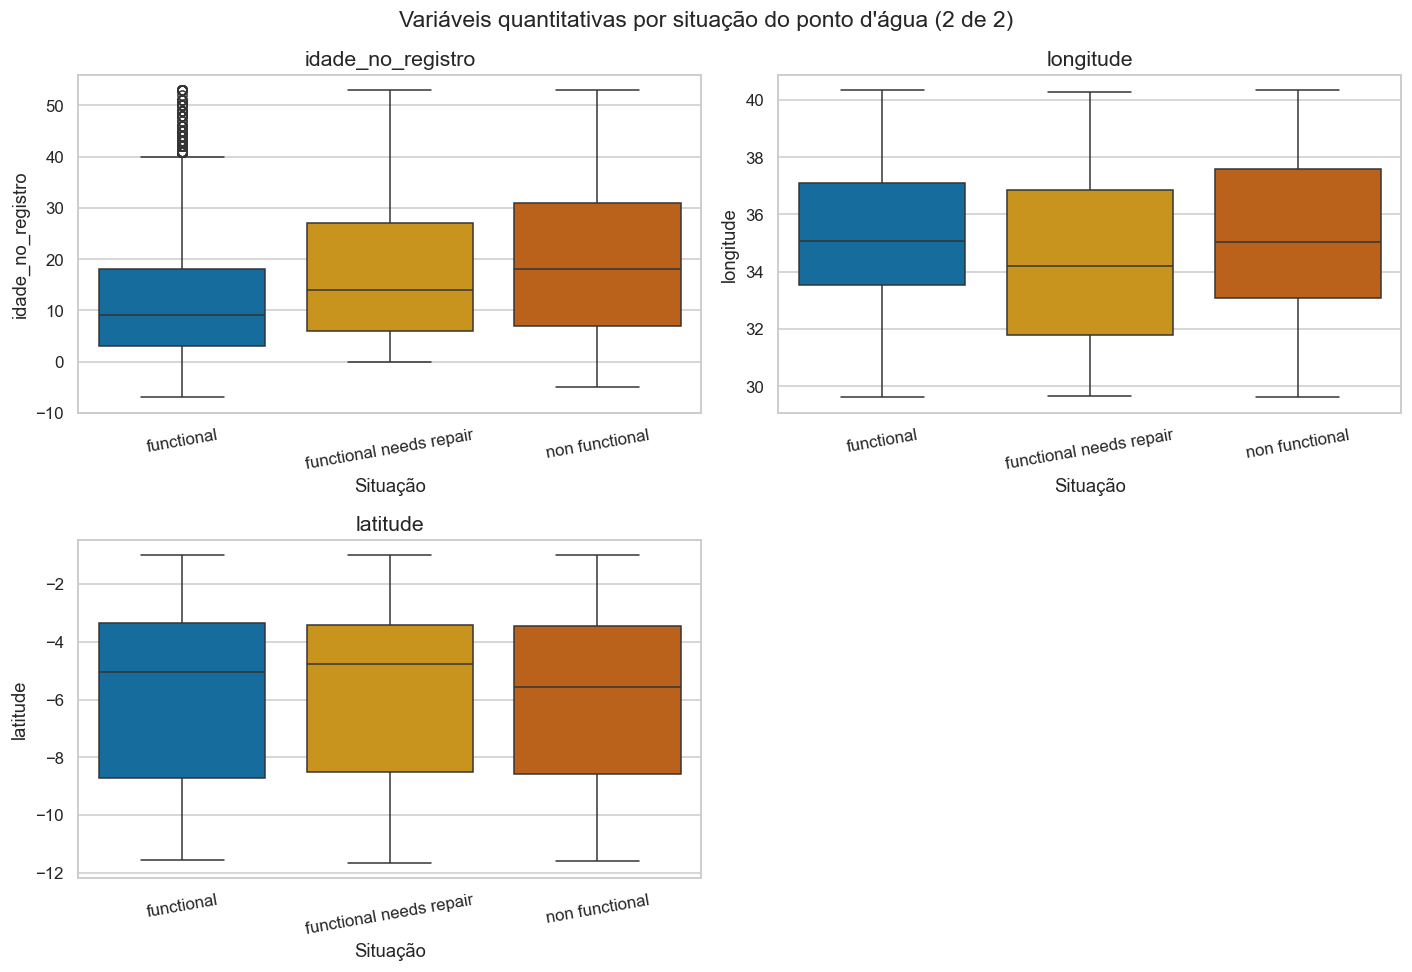

In [30]:
# [IA] Claude Code – gráfico: cada quantitativa por classe (boxplot), duas figuras
cols_box = ["amount_tsh", "gps_height", "population", "construction_year",
            "idade_no_registro", "longitude", "latitude"]
dados_box = viz[cols_box].assign(status=df[COL_ALVO])


def boxplots_por_classe(colunas, nome, parte):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, col in zip(axes.flat, colunas):
        d = dados_box[[col, "status"]].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            d = d[d[col] > 0]
        sns.boxplot(data=d, x="status", y=col, hue="status", order=STATUS_ORDEM,
                    palette=STATUS_CORES, legend=False, ax=ax)
        if usar_log:
            ax.set_yscale("log")
        ax.set_title(col + (" (> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel("Situação")
        ax.set_ylabel(col)
        ax.tick_params(axis="x", labelrotation=10)
    for ax in axes.flat[len(colunas):]:
        ax.axis("off")
    fig.suptitle(f"Variáveis quantitativas por situação do ponto d'água ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


boxplots_por_classe(cols_box[:4], "04_quantitativas_por_classe_1", 1)
boxplots_por_classe(cols_box[4:], "04_quantitativas_por_classe_2", 2)

### 4.3 Tabela: proporção de status por categoria (`quantity`)

Demonstra a função `proporcao_status()` aplicada à coluna `quantity`, mostrando o percentual de cada classe dentro de cada categoria e o total de registros (`n`).

> **Como ler:** Cada linha é uma categoria. As colunas de situação mostram o percentual de pontos d'água da categoria naquela situação (a linha soma 100%), e `n` é o total de pontos d'água da categoria.

In [31]:
# [IA] Claude Code – função: proporção de cada status dentro das categorias de uma coluna
def proporcao_status(coluna):
    """Tabela com o % de cada status por categoria (linhas somam 100) e o n de cada categoria."""
    valores = df[coluna].astype("string").fillna("(ausente)")
    tabela = pd.crosstab(valores, df[COL_ALVO], normalize="index").mul(100)[STATUS_ORDEM]
    tabela["n"] = valores.value_counts()
    return tabela.sort_values("n", ascending=False)


com_titulo(
    proporcao_status("quantity").round(1).style.background_gradient(
        subset=STATUS_ORDEM, cmap="Blues", vmin=0, vmax=100).format(
        {**{s: "{:.1f}%" for s in STATUS_ORDEM}, "n": "{:,.0f}"}),
    "Tabela 4.3 — Proporção de status_group por categoria de quantity (%)"
)

status_group,functional,functional needs repair,non functional,n
quantity,,,,
enough,65.2%,7.2%,27.5%,"33,186"
insufficient,52.3%,9.6%,38.1%,"15,129"
dry,2.5%,0.6%,96.9%,"6,246"
seasonal,57.4%,10.3%,32.3%,"4,050"
unknown,27.0%,1.8%,71.2%,789


### 4.4 Barras 100% empilhadas por categoria

Exibe gráficos de barras 100% empilhadas com a proporção de cada classe de `status_group` dentro das categorias das principais variáveis qualitativas agregadas.

> **Como ler:** Cada barra é uma categoria (`n` = número de pontos d'água dela). As cores dividem 100% da barra entre as três situações.

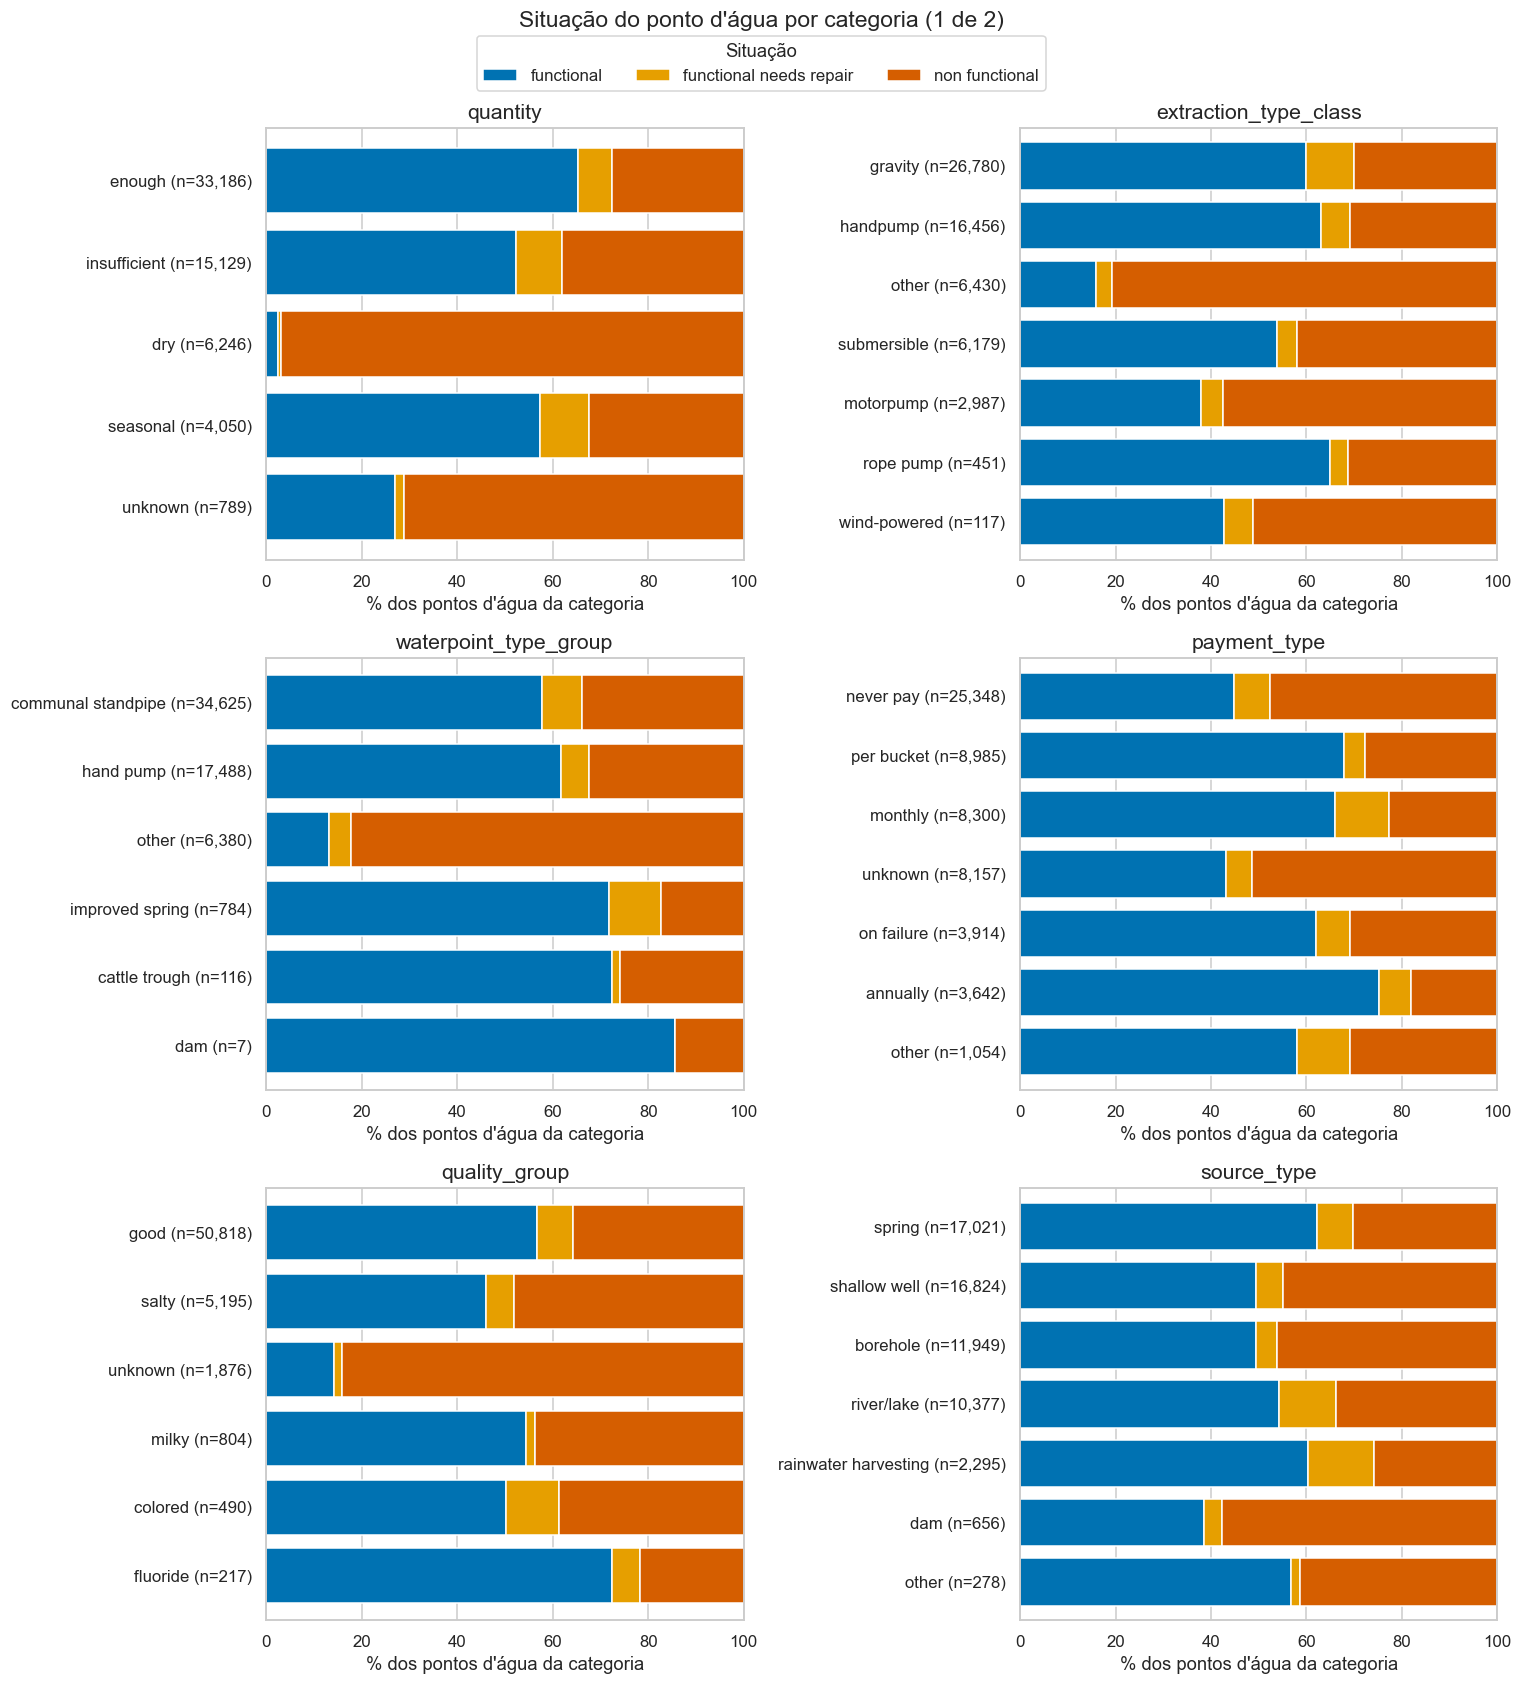

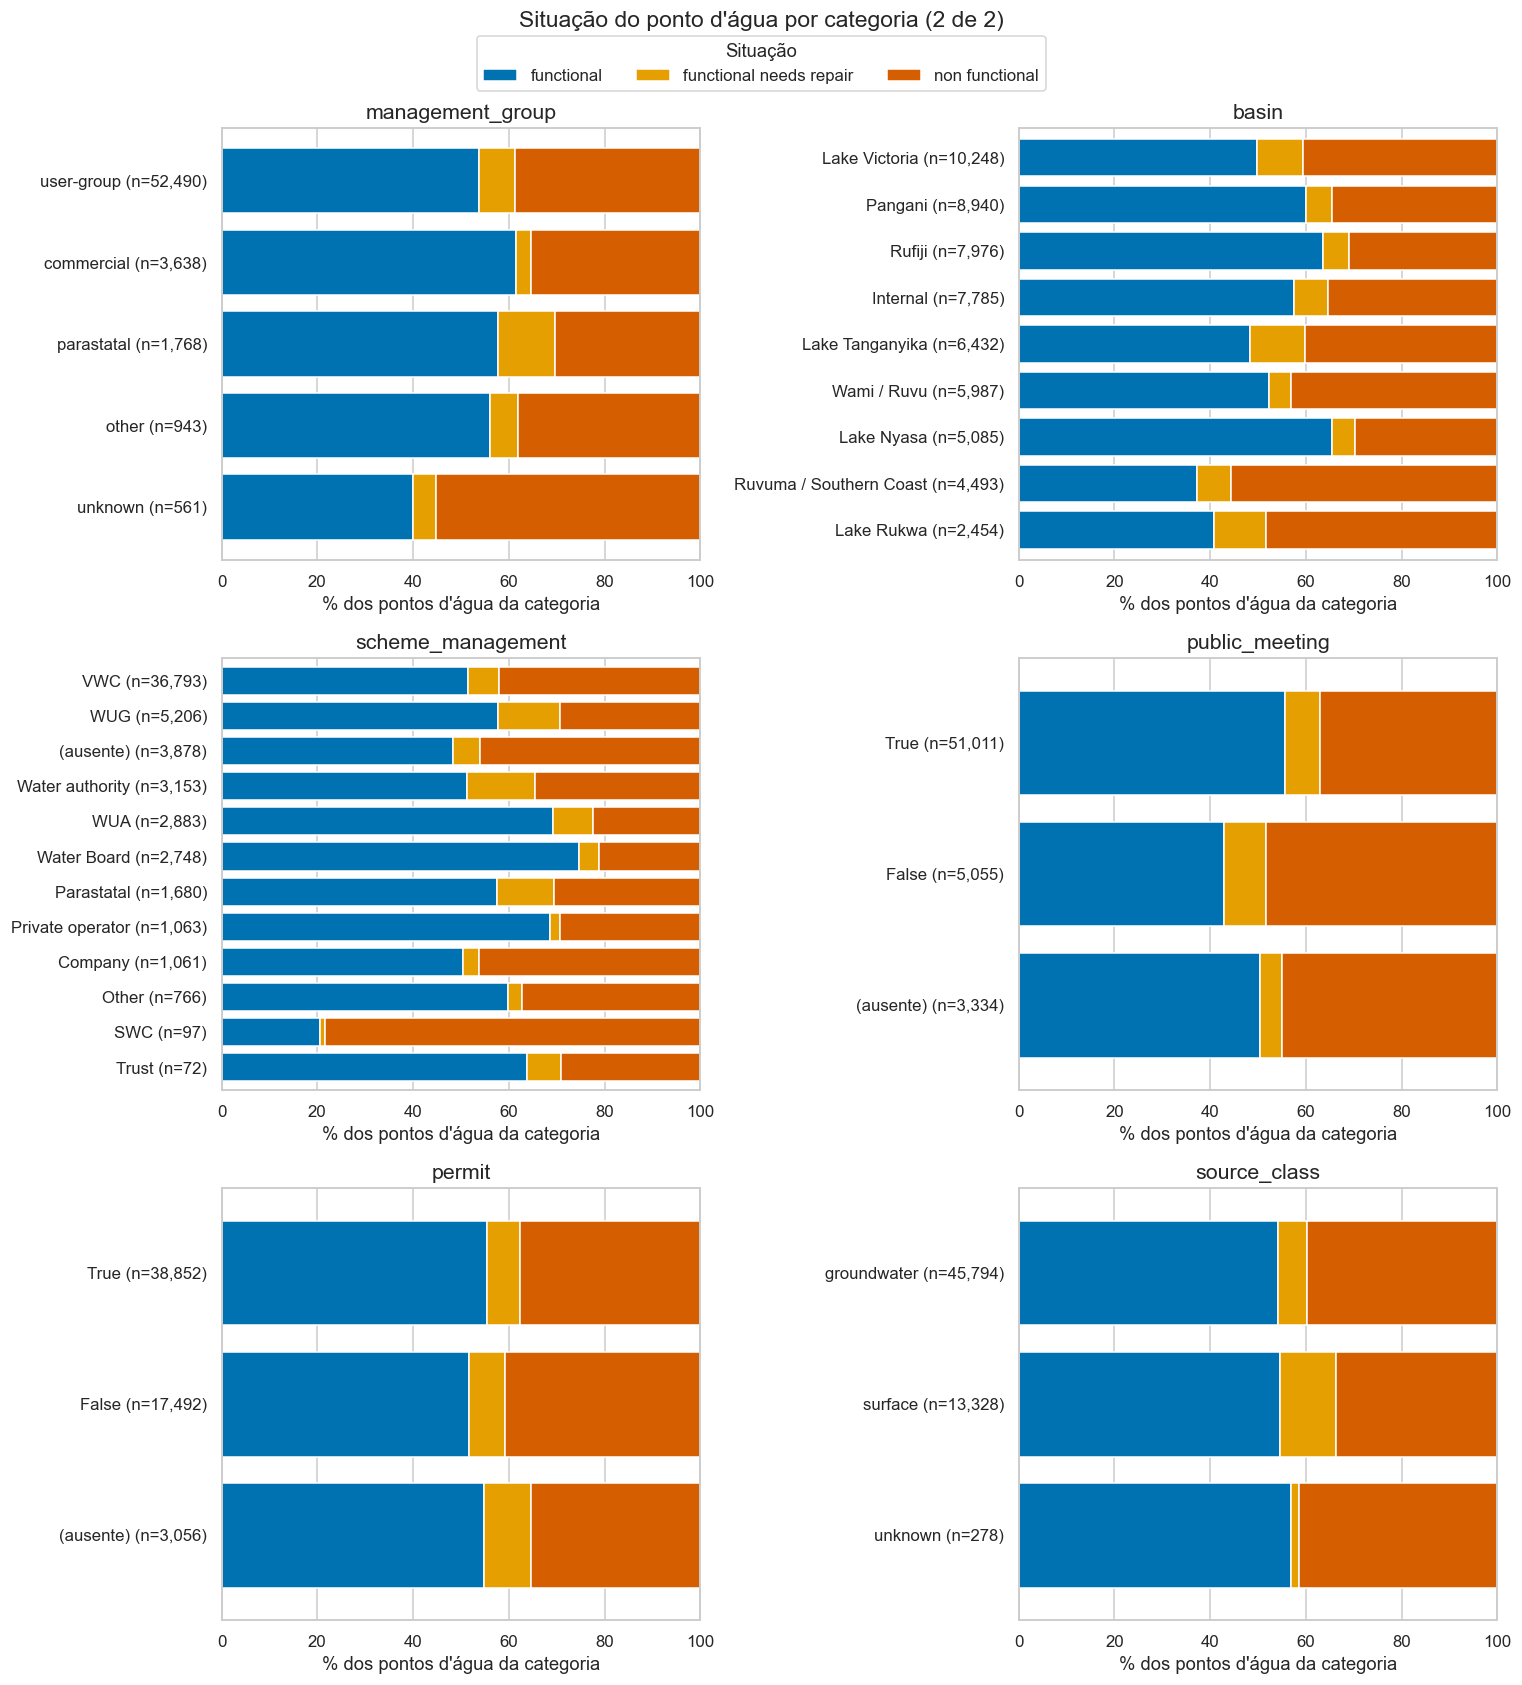

In [32]:
# [IA] Claude Code – gráfico: barras 100% empilhadas do status por categoria (versões agregadas das famílias), 6 por figura
cols_rel = ["quantity", "extraction_type_class", "waterpoint_type_group", "payment_type",
            "quality_group", "source_type", "management_group", "basin",
            "scheme_management", "public_meeting", "permit", "source_class"]

POR_FIGURA = 6
n_partes = int(np.ceil(len(cols_rel) / POR_FIGURA))
for parte, inicio in enumerate(range(0, len(cols_rel), POR_FIGURA), start=1):
    grupo = cols_rel[inicio:inicio + POR_FIGURA]
    fig, axes = plt.subplots(3, 2, figsize=(14, 15))
    for ax, col in zip(axes.flat, grupo):
        tabela = proporcao_status(col)
        tabela[STATUS_ORDEM].iloc[::-1].plot.barh(
            stacked=True, ax=ax, color=[STATUS_CORES[s] for s in STATUS_ORDEM], width=0.8, legend=False)
        ax.set_yticklabels([f"{i} (n={n:,})" for i, n in tabela["n"].iloc[::-1].items()])
        ax.set_title(col)
        ax.set_xlabel("% dos pontos d'água da categoria")
        ax.set_ylabel("")
        ax.set_xlim(0, 100)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Situação", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.01))
    fig.suptitle(f"Situação do ponto d'água por categoria ({parte} de {n_partes})", fontsize=15, y=1.02)
    fig.tight_layout()
    salvar(fig, f"04_status_por_categoria_{parte}")
    plt.show()

### 4.5 Versão interativa: situação por categoria (Plotly)

Mesmo gráfico das barras 100% empilhadas, mas com **menu** para escolher a coluna e **dica ao passar o mouse** (mostra o valor exato). Precisa de internet para carregar o Plotly. No GitHub esta célula não aparece (só no Jupyter ou no Colab).

> **Como ler:** escolha a coluna no menu no alto do gráfico. Cada barra é uma categoria, e as cores dividem 100% da barra entre as três situações.

In [33]:
# [IA] Claude Code + Gemini – versão interativa (Plotly): renderizador compatível com VS Code/Jupyter/HTML e layout ajustado
import plotly.graph_objects as go
import plotly.io as pio

if "google.colab" not in sys.modules:   # no Colab o Plotly já escolhe o renderizador certo
    pio.renderers.default = "plotly_mimetype+notebook_connected"   # funciona no VS Code, Jupyter e HTML exportado

fig = go.Figure()
n_status = len(STATUS_ORDEM)
for k, col in enumerate(cols_rel):
    tabela = proporcao_status(col).iloc[::-1]
    rotulos = [f"{i} (n={n:,})" for i, n in tabela["n"].items()]
    for status in STATUS_ORDEM:
        fig.add_trace(go.Bar(
            x=tabela[status], y=rotulos, orientation="h", name=status,
            marker_color=STATUS_CORES[status], visible=(k == 0),
            legendgroup=status, showlegend=(k == 0),
            hovertemplate="%{y}<br>" + status + ": %{x:.1f}%<extra></extra>",
        ))

botoes = []
for k, col in enumerate(cols_rel):
    visivel = [j // n_status == k for j in range(len(cols_rel) * n_status)]
    titulo_col = f"Situação do ponto d'água por categoria: {col} ({glossario(col)})"
    botoes.append(dict(
        label=col,
        method="update",
        args=[
            {"visible": visivel, "showlegend": visivel},
            {"title": {"text": titulo_col}},
        ],
    ))

fig.update_layout(
    barmode="stack",
    title=dict(
        text=f"Situação do ponto d'água por categoria: {cols_rel[0]} ({glossario(cols_rel[0])})",
        x=0.0,
        y=0.97,
    ),
    xaxis=dict(title="% dos pontos d'água da categoria", range=[0, 100]),
    yaxis=dict(title="", automargin=True),
    legend=dict(title="Situação", orientation="h", x=0.0, y=-0.16),
    updatemenus=[dict(
        buttons=botoes,
        direction="down",
        showactive=True,
        x=0.0,
        y=1.14,
        xanchor="left",
        yanchor="top",
    )],
    height=600,
    margin=dict(l=20, r=20, t=135, b=85),
)
fig.show()

### 4.6 Situação dos pontos d'água por região (%)

Cruza a localização regional (`region`) com a variável-alvo, exibindo o percentual de cada situação funcional dentro de cada uma das 21 regiões.

> **Como ler:** As linhas são as regiões e o número é o percentual de cada situação dentro da região (cada linha soma 100%).

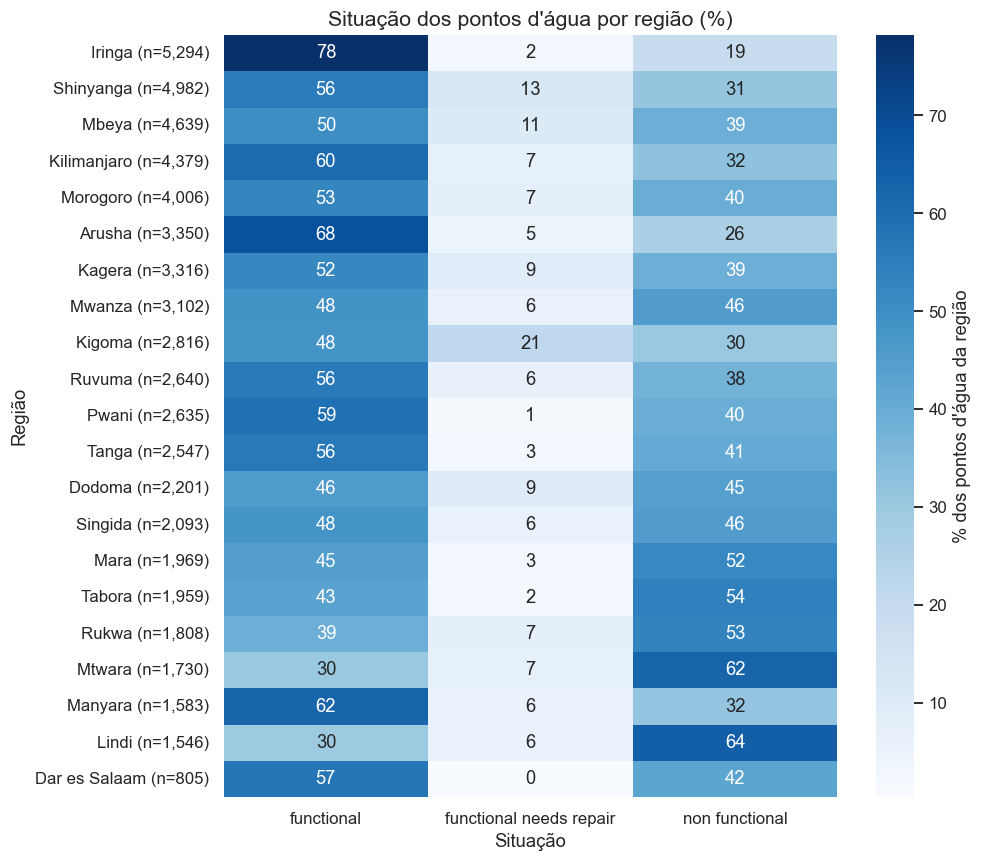

In [34]:
# [IA] Claude Code – gráfico: % de cada status por região
tabela_regiao = proporcao_status("region")

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(tabela_regiao[STATUS_ORDEM], annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% dos pontos d'água da região"}, ax=ax)
ax.set_yticklabels([f"{r} (n={n:,})" for r, n in tabela_regiao["n"].items()], rotation=0)
ax.set_title("Situação dos pontos d'água por região (%)")
ax.set_xlabel("Situação")
ax.set_ylabel("Região")
salvar(fig, "04_status_por_regiao")
plt.show()

### 4.7 Mapa geográfico por status (`longitude` × `latitude`)

Plota a distribuição espacial dos pontos d'água pelas coordenadas válidas (`longitude` × `latitude`), coloridos conforme o `status_group`.

> **Como ler:** Cada ponto é um ponto d'água (longitude no eixo x, latitude no eixo y). Os pontos cinza são todos; os coloridos são os da situação indicada no título do painel.

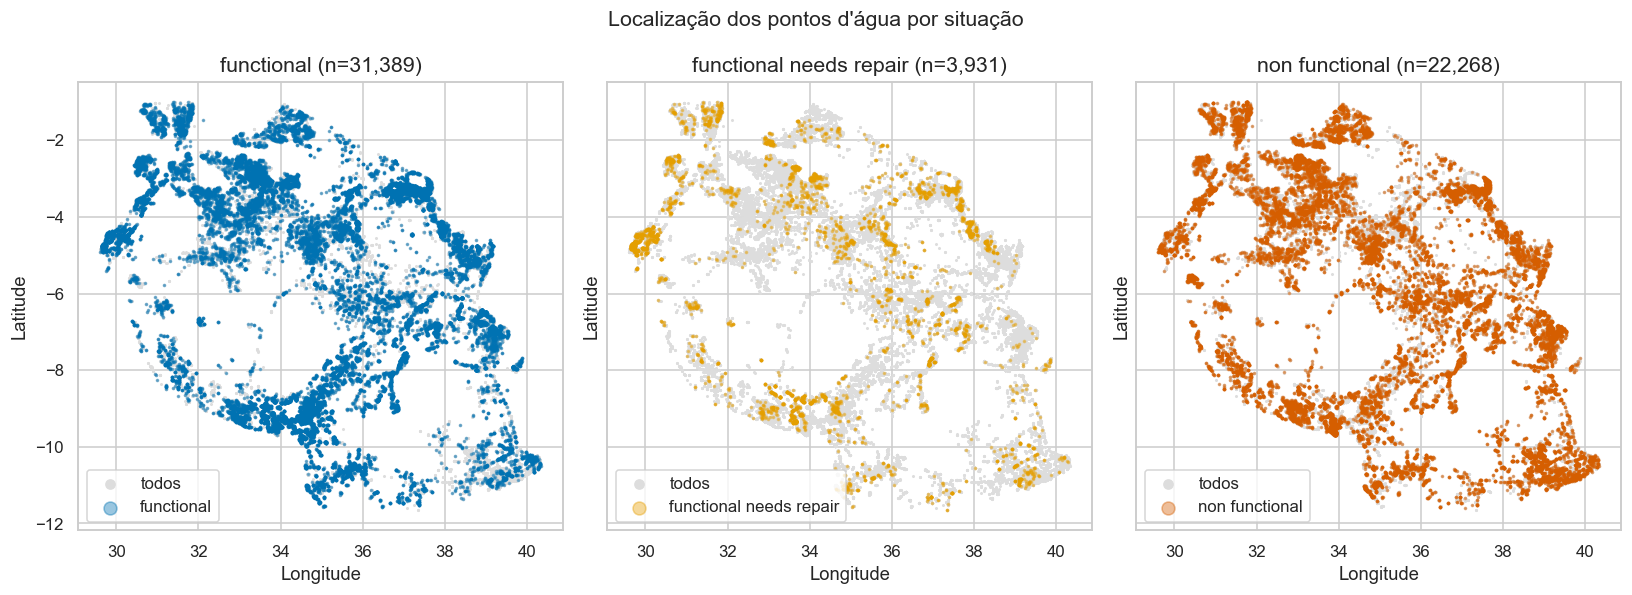

In [35]:
# [IA] Claude Code – gráfico: localização dos pontos d'água por status (coordenadas válidas)
geo = viz[["longitude", "latitude"]].assign(status=df[COL_ALVO]).dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharex=True, sharey=True)
for ax, status in zip(axes, STATUS_ORDEM):
    ax.scatter(geo["longitude"], geo["latitude"], s=1, color="#DDDDDD", label="todos")
    sub = geo[geo["status"] == status]
    ax.scatter(sub["longitude"], sub["latitude"], s=2, alpha=0.4,
               color=STATUS_CORES[status], label=status)
    ax.set_title(f"{status} (n={len(sub):,})")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(loc="lower left", markerscale=6)
fig.suptitle("Localização dos pontos d'água por situação", fontsize=14)
fig.tight_layout()
salvar(fig, "04_mapa_por_status")
plt.show()

### 4.8 Visão multivariada (`quantity`, `extraction_type_class` e `waterpoint_type_group`)

Função para cruzar **duas** variáveis qualitativas e ver o % de um status em cada combinação. Abaixo, um exemplo; troque as colunas e o status para explorar outras combinações.

> **Como ler:** As linhas e as colunas são as categorias de duas variáveis. O número é o percentual de pontos d'água na situação escolhida (por padrão, `non functional`) em cada combinação. Células em branco têm menos de 50 linhas.

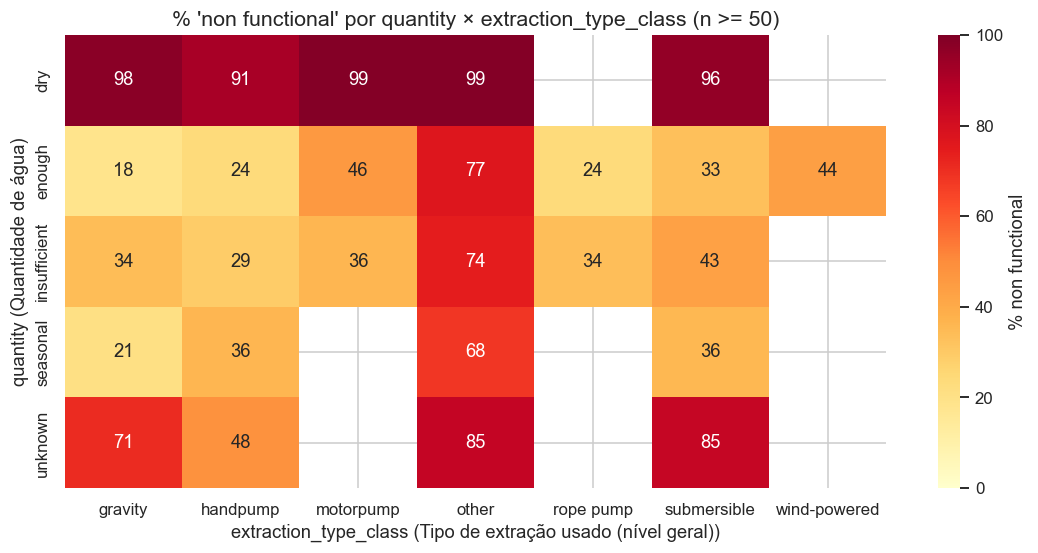

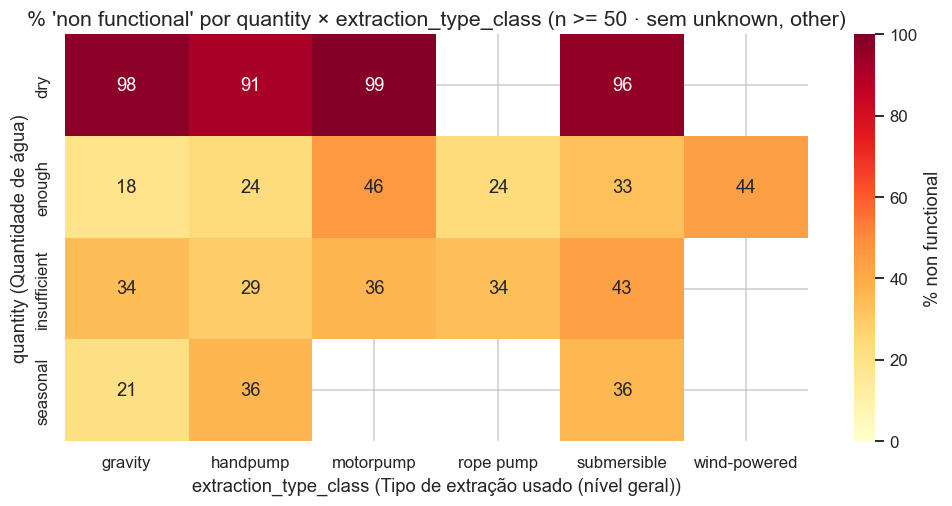

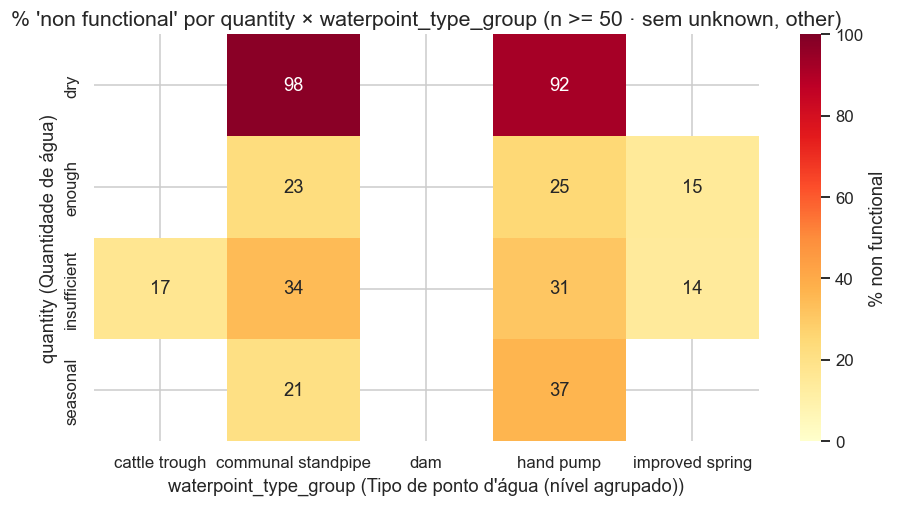

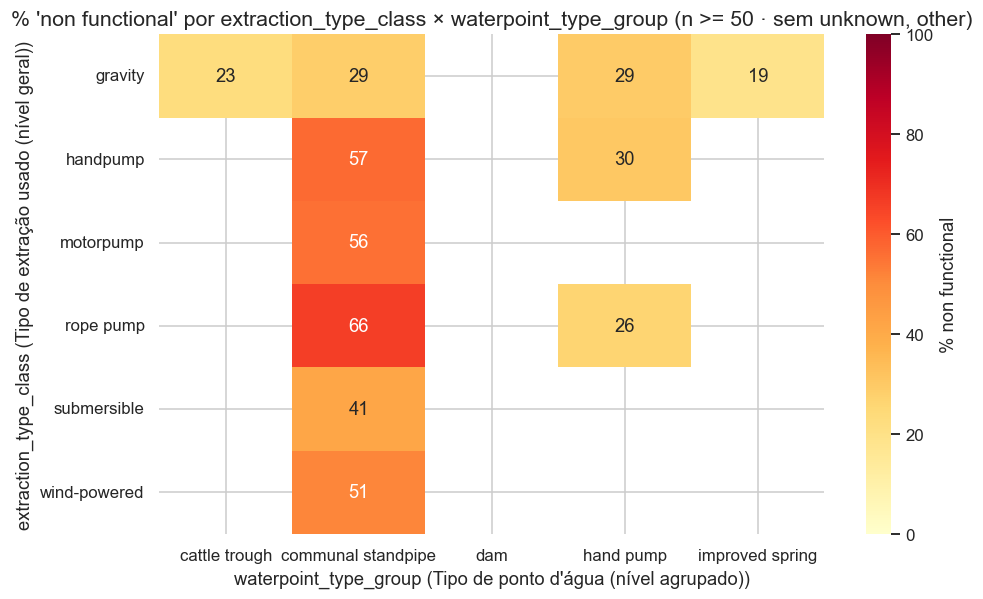

In [36]:
# [IA] Claude Code + Gemini – função: % de um status em cada combinação de duas colunas qualitativas (paleta YlOrRd + opção de filtrar categorias)
def taxa_status(linha, coluna, status="non functional", n_min=50, excluir=None, cmap="YlOrRd"):
    """Heatmap do % de `status` em cada combinação (linha x coluna). Combinações com menos de n_min linhas ficam em branco."""
    base = df
    if excluir:
        base = df[~df[linha].isin(excluir) & ~df[coluna].isin(excluir)]
    grupos = base.groupby([linha, coluna])[COL_ALVO]
    taxa = grupos.apply(lambda s: (s == status).mean() * 100).unstack()
    n = grupos.size().unstack()
    taxa = taxa.where(n >= n_min)

    fig, ax = plt.subplots(figsize=(1.15 * taxa.shape[1] + 4, 0.55 * taxa.shape[0] + 2.6))
    sns.heatmap(taxa, annot=True, fmt=".0f", cmap=cmap, vmin=0, vmax=100,
                cbar_kws={"label": f"% {status}"}, ax=ax)
    sufixo = f" · sem {', '.join(excluir)}" if excluir else ""
    ax.set_title(f"% '{status}' por {linha} × {coluna} (n >= {n_min}{sufixo})")
    ax.set_xlabel(f"{coluna} ({glossario(coluna)})")
    ax.set_ylabel(f"{linha} ({glossario(linha)})")
    return fig, ax


# 1) quantity × extraction_type_class (completo + filtrado)
fig, ax = taxa_status("quantity", "extraction_type_class")
salvar(fig, "04_multivariada_quantity_extraction")
plt.show()

fig, ax = taxa_status("quantity", "extraction_type_class", excluir=("unknown", "other"))
salvar(fig, "04_multivariada_quantity_extraction_limpo")
plt.show()

# 2) quantity × waterpoint_type_group (filtrado sem unknown/other)
fig, ax = taxa_status("quantity", "waterpoint_type_group", excluir=("unknown", "other"))
salvar(fig, "04_multivariada_quantity_waterpoint")
plt.show()

# 3) extraction_type_class × waterpoint_type_group (filtrado sem unknown/other)
fig, ax = taxa_status("extraction_type_class", "waterpoint_type_group", excluir=("unknown", "other"))
salvar(fig, "04_multivariada_extraction_waterpoint")
plt.show()

### ✅ [AUTORAL] 4.9 Interpretação — Análise Relacional

> Dá para notar que o poço seco (`quantity == dry`, com 96,9% de `non functional`) é o indicador mais forte de que o ponto não funciona, o que é bem intuitivo. Também chama atenção o tipo de tecnologia usada: mesmo quando a quantidade de água é suficiente (`enough`), `motorpump` (45,9% `non functional`, n=1.539), `wind-powered` (44,1%, apesar da amostra pequena, n=59) e `submersible` (33,0%, n=3.874) falham muito mais do que opções mais simples como `gravity` (18,4%) e `handpump` (23,6%). Como são sistemas motorizados ou mecanicamente mais complexos, provavelmente dependem de manutenção mais frequente e especializada.

> Em `quantity`, `dry` (96,9%) e `unknown` (71,2%) dominam a associação com pontos não funcionais, enquanto `insufficient` (38,1%) fica bem próxima da média geral do dataset (38,4%), um pouco acima de `seasonal` (32,3%) e `enough` (27,5%). O resto varia conforme o mecanismo da bomba e a sazonalidade. Já a categoria `other` em `extraction_type_class` (76,7% `non functional` mesmo com `enough`) pode indicar meios alternativos ou improvisados, mas precisaria de uma investigação mais profunda.

> A qualidade da água (`quality_group`) tem associação bem menor no geral do que quantidade ou tipo de extração, embora `salty` (n=5.195) suba para 48,2% de `non functional` (contra 35,7% em `good`) e `unknown` (n=1.876) chegue a 84,1%.

> Nas quantitativas (Seções 4.1 e 4.2), as correlações de Spearman entre pares numéricos são modestas e só `gps_height × longitude` (−0,63) passa de 0,4 em módulo. Diferente do que parecia intuitivo no começo, a concentração populacional (`population` > 0) não diferencia bombas funcionais das não funcionais: as duas classes têm a mesma mediana de 150 habitantes (só `functional needs repair` sobe um pouco para 200). Quem separa bem as três classes nos boxplots é a variável derivada `idade_no_registro`, com mediana de 9 anos em `functional`, 14 anos em `functional needs repair` e 18 anos em `non functional`, o dobro das funcionais.

> Na parte geográfica (Seções 4.6 e 4.7), também existe uma diferença grande entre regiões: Iringa (78,2% `functional` e 19,5% `non functional`) e Arusha (68,5% `functional` e 26,3% `non functional`) têm os melhores cenários, enquanto Lindi (64,2% `non functional`), Mtwara (62,4%) e Tabora (54,4%) concentram as maiores taxas de bombas inoperantes.

<a id="secao-7"></a>

## 5. Outliers

Identificação pelo critério do IQR (Aula 09), calculado sobre os valores válidos (cópia `viz`). Também listamos os maiores valores e casos impossíveis.

### 5.1 Tabela de outliers pelo critério IQR (1,5 × IQR)

Calcula os quartis, o intervalo interquartil (IQR), os limites da regra `1,5 × IQR` e a contagem/percentual de outliers para cada variável quantitativa.

> **Como ler:** `q1` e `q3` são os quartis, `iqr` = `q3` − `q1`, `lim_inf` e `lim_sup` são `q1` − 1,5·`iqr` e `q3` + 1,5·`iqr`, e `n_outliers` conta os valores fora desses limites.

In [37]:
# [IA] Claude Code + Gemini – tabela de outliers pelo IQR (1,5 x IQR, com coluna glossario)
def resumo_iqr(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (s < lim_inf) | (s > lim_sup)
    return pd.Series({"n_validos": len(s), "q1": q1, "q3": q3, "iqr": iqr,
                      "lim_inf": lim_inf, "lim_sup": lim_sup, "min": s.min(), "max": s.max(),
                      "n_outliers": int(fora.sum()), "pct_outliers": round(fora.mean() * 100, 2)})


cols_out = ["amount_tsh", "gps_height", "population", "construction_year", "idade_no_registro"]
tab_out = pd.DataFrame({c: resumo_iqr(viz[c]) for c in cols_out}).T
cols_num_out = list(tab_out.columns)
tab_out.insert(0, "glossario", [glossario(c) for c in tab_out.index])
com_titulo(tab_out.style.format("{:,.2f}", subset=cols_num_out), "Tabela 5.1 — Detecção de outliers pelo critério 1,5 × IQR")

,glossario,n_validos,q1,q3,iqr,lim_inf,lim_sup,min,max,n_outliers,pct_outliers
amount_tsh,Total static head: água disponível no ponto (unidade a confirmar),"59,400.00",0.00,20.00,20.00,-30.00,50.00,0.00,"350,000.00","11,161.00",18.79
gps_height,Altitude do poço (unidade a confirmar),"38,962.00",393.00,"1,498.00","1,105.00","-1,264.50","3,155.50",-90.00,"2,770.00",0.00,0.00
population,População ao redor do poço,"38,019.00",40.00,324.00,284.00,-386.00,750.00,1.00,"30,500.00","2,473.00",6.50
construction_year,Ano de construção do ponto d'água,"38,691.00","1,987.00","2,008.00",21.00,"1,955.50","2,039.50","1,960.00","2,013.00",0.00,0.00
idade_no_registro,Derivada: ano do registro menos construction_year,"38,691.00",5.00,25.00,20.00,-25.00,55.00,-7.00,53.00,0.00,0.00


### 5.2 Boxplots das variáveis quantitativas

Plota os boxplots das variáveis quantitativas (com escala logarítmica nas mais assimétricas) para visualizar dispersão e pontos fora dos limites do IQR.

> **Como ler:** Cada boxplot é uma variável: a caixa vai do 1º ao 3º quartil, a linha dentro é a mediana e os pontos são valores fora dos limites do IQR.

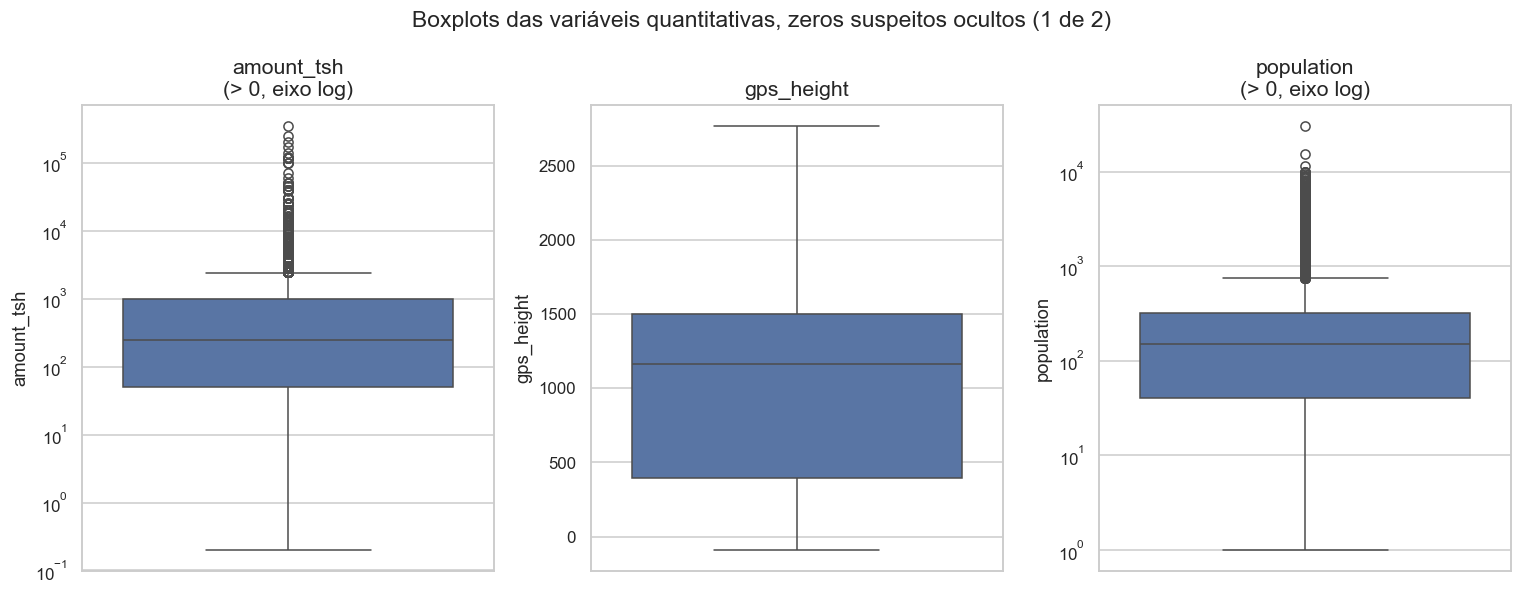

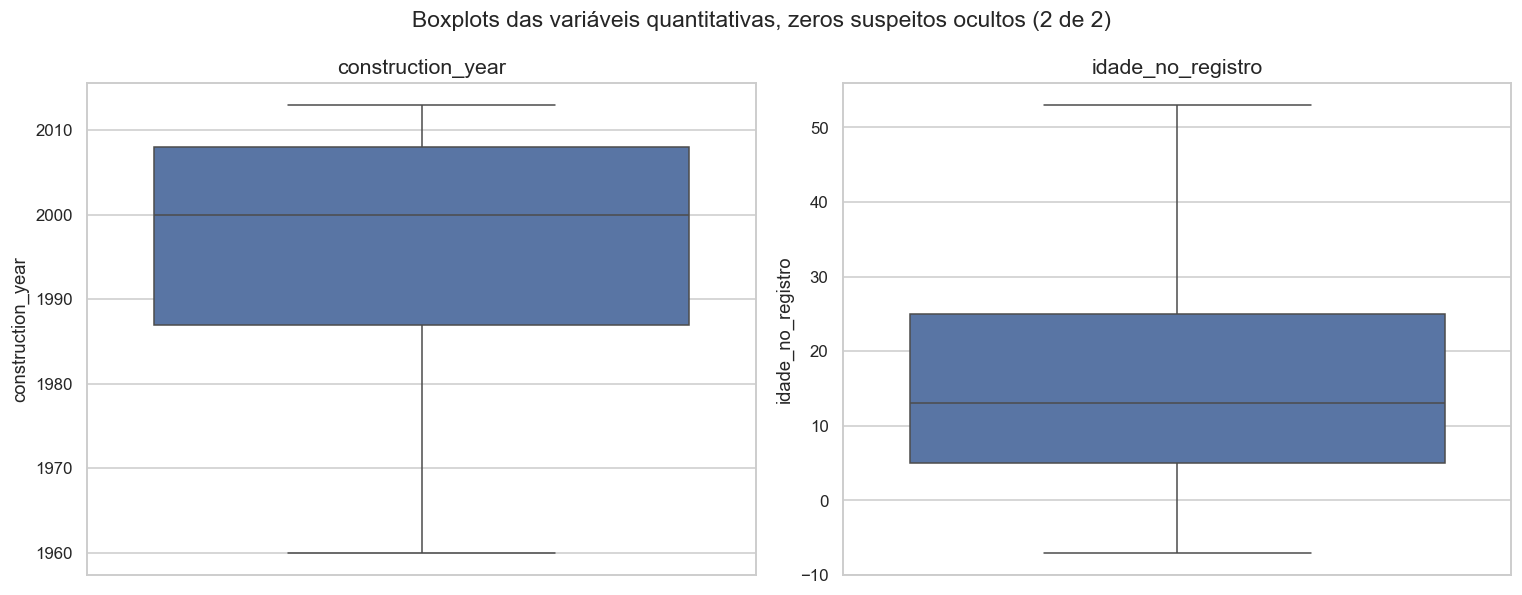

In [38]:
# [IA] Claude Code – gráfico: boxplots das quantitativas (valores válidos), duas figuras
def boxplots_outliers(colunas, nome, parte):
    fig, axes = plt.subplots(1, len(colunas), figsize=(14, 5.5))
    for ax, col in zip(axes, colunas):
        d = viz[col].dropna()
        usar_log = col in COLS_LOG
        if usar_log:
            d = d[d > 0]
        sns.boxplot(y=d, ax=ax, color="#4C72B0")
        if usar_log:
            ax.set_yscale("log")
        ax.set_title(col + ("\n(> 0, eixo log)" if usar_log else ""))
        ax.set_xlabel("")
        ax.set_ylabel(col)
    fig.suptitle(f"Boxplots das variáveis quantitativas, zeros suspeitos ocultos ({parte} de 2)", fontsize=15)
    fig.tight_layout()
    salvar(fig, nome)
    plt.show()


boxplots_outliers(cols_out[:3], "05_boxplots_outliers_1", 1)
boxplots_outliers(cols_out[3:], "05_boxplots_outliers_2", 2)

### 5.3 Inspeção dos extremos (Top 10 `amount_tsh` e `population`)

Lista os 10 maiores valores registrados de `amount_tsh` e de `population`, acompanhados de atributos de contexto para inspeção manual dos extremos.

> **Como ler:** Os 10 maiores valores de `amount_tsh` e de `population`, com outras colunas para dar contexto.

In [39]:
# [IA] Claude Code – maiores valores de amount_tsh e population (para inspecionar os extremos)
colunas_ver = ["amount_tsh", "population", "region", "lga", "extraction_type_class",
               "waterpoint_type", "quantity", COL_ALVO]
display(com_titulo(df.nlargest(10, "amount_tsh")[colunas_ver], "Tabela 5.3a — 10 maiores valores registrados de amount_tsh"))
display(com_titulo(df.nlargest(10, "population")[colunas_ver], "Tabela 5.3b — 10 maiores valores registrados de population"))

,amount_tsh,population,region,lga,extraction_type_class,waterpoint_type,quantity,status_group
10812,350000.000000,886,Singida,Singida Rural,motorpump,communal standpipe,insufficient,functional
22191,250000.000000,80,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
22817,200000.000000,800,Tanga,Tanga,submersible,communal standpipe,enough,functional
45067,170000.000000,150,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
9961,138000.000000,587,Pwani,Bagamoyo,submersible,communal standpipe,enough,functional
9917,120000.000000,120,Kilimanjaro,Same,gravity,communal standpipe,enough,functional
5558,117000.000000,60,Iringa,Njombe,gravity,communal standpipe,enough,functional
10615,117000.000000,150,Iringa,Njombe,gravity,communal standpipe multiple,enough,functional
37459,117000.000000,20,Iringa,Njombe,gravity,communal standpipe,enough,functional
44381,117000.000000,600,Iringa,Njombe,gravity,communal standpipe,enough,functional


,amount_tsh,population,region,lga,extraction_type_class,waterpoint_type,quantity,status_group
30537,0.000000,30500,Tanga,Muheza,handpump,hand pump,insufficient,functional
14308,0.000000,15300,Manyara,Kiteto,submersible,communal standpipe,insufficient,functional needs repair
51398,50.000000,11463,Pwani,Kibaha,motorpump,communal standpipe,enough,functional
30231,0.000000,10000,Mara,Serengeti,handpump,hand pump,enough,functional
31363,30.000000,10000,Rukwa,Mpanda,submersible,hand pump,enough,functional
56742,500.000000,10000,Mara,Tarime,other,improved spring,enough,functional
12784,0.000000,9865,Dar es Salaam,Kinondoni,submersible,communal standpipe,enough,non functional
13725,0.000000,9500,Arusha,Arusha Urban,other,other,enough,functional needs repair
31473,50.000000,9000,Singida,Manyoni,motorpump,communal standpipe multiple,enough,non functional
48725,0.000000,9000,Mara,Serengeti,gravity,communal standpipe multiple,enough,functional


### 5.4 Valores impossíveis ou inconsistentes

Verifica ocorrências de valores inconsistentes com o domínio (como ano de construção posterior ao ano de registro e altitudes negativas).

> **Como ler:** Dois casos que não deveriam existir: ponto d'água construído depois do registro e altitude negativa (com as regiões onde isso acontece).

In [40]:
# [IA] Claude Code – valores impossíveis ou estranhos
print("Construção depois do registro:", (viz["idade_no_registro"] < 0).sum())
print("gps_height negativo:", (df["gps_height"] < 0).sum(),
      "| mínimo:", df["gps_height"].min())
print("Regiões com gps_height negativo:")
df.loc[df["gps_height"] < 0, "region"].value_counts()

Construção depois do registro: 9
gps_height negativo: 1496 | mínimo: -90
Regiões com gps_height negativo:


region
Pwani            721
Mtwara           249
Lindi            187
Dar es Salaam    180
Tanga            159
Name: count, dtype: int64

### ✅ [AUTORAL] 5.5 Decisão sobre os outliers

> Os valores impossíveis no mundo real vão ser tratados seguindo a orientação da Aula 09 (pág. 26: corrigir quando possível e remover como última opção). As 9 linhas com idade negativa (`construction_year > date_recorded`) são erro claro de dado e já saem junto com o corte dos 31 registros de 2002 e 2004. Já os 1.496 registros com altitude negativa (`gps_height < 0`, mediana de −18 m e mínimo de −90 m) ficam concentrados nas 5 regiões litorâneas da Tanzânia (Pwani, Mtwara, Lindi, Dar es Salaam e Tanga), o que indica margem de erro vertical do GPS perto do nível do mar; em vez de apagar 1.496 bombas do litoral, esses valores negativos serão corrigidos para `0` (depois da imputação dos `gps_height == 0` originais).

> Já os valores extremos positivos (incluindo o `0` em `amount_tsh`) ainda fazem sentido na prática. Em `amount_tsh` (18,8% marcados pelo IQR, máximo de 350.000 e sem unidade oficial) e `population` (7,4% pelo IQR, máximo de 30.500), valores muito altos podem refletir construções grandes, reservatórios, maior investimento em uma área específica ou maior densidade populacional; e os zeros podem indicar fontes quebradas, precisando de reparo, sem medição ou fora de uso.

> Minha decisão é manter os valores que estão dentro da possibilidade real. Os modelos definidos para o projeto (`RandomForestClassifier` e `DecisionTreeClassifier` como baseline, da Aula 25, com One-Hot Encoding para baixa cardinalidade e Target Encoding para alta cardinalidade dentro de um Pipeline ajustado só no treino, da Aula 26) funcionam por cortes de limiar e não são afetados por outliers nas variáveis numéricas. Manter esses dados preserva a representatividade real sem prejudicar o modelo, evitando perder milhares de registros que seriam jogados fora em um corte mecânico pelo IQR.

> Na parte de visualização de dados (gráficos da EDA, relatório e Streamlit), dá para compensar esses extremos usando mediana (Aula 09) e escalas logarítmicas (Aula 26), técnicas vistas em sala de aula que deixam a leitura limpa sem apagar dados válidos.

<a id="secao-8"></a>

## 6. Tratamento e exportação

Aplicar aqui **apenas** os tratamentos decididos e justificados nas seções 1 a 5, e exportar para `data/parte_especifica/clean/pump_it_up_clean.csv` (lido pelo dashboard e pelo classificador).

Decisões fechadas pelo grupo:
- [x] Duplicadas (36 linhas ignorando `id`) e recorte temporal (31 registros residuais de 2002/2004 com todas as 9 idades negativas): remover.
- [x] Zeros suspeitos MAR (`population`, `construction_year`, `gps_height`, `longitude`/`latitude`): converter em `NaN`, salvar flags `ausente_*` (evita *data leakage* no classificador) e imputar em cascata pela mediana (`lga` → `region` → `basin`).
- [x] `gps_height < 0` (1.496 registros no litoral): corrigir para `0` **após** a imputação dos `gps_height == 0` originais.
- [x] `scheme_name` (48,5% ausente), `num_private` (98,7% zero), `recorded_by` (constante), `region_code`, `district_code`, `wpt_name` e `subvillage`: descartar.
- [x] Colunas redundantes: manter apenas as versões generalizadas (`extraction_type_class`, `quantity`, `payment_type`, `quality_group`, `source_class`, `waterpoint_type_group`, `management_group`) e `scheme_management`.
- [x] Categóricas com `NaN` e `'0'`/`'-'` (`scheme_management`, `installer`, `funder`, `public_meeting`, `permit`): preencher com `"desconhecido"` e aplicar `strip().lower()` em `funder` e `installer`.
- [x] Alta cardinalidade mantida (`lga`, `ward`, `funder`, `installer`): pronta para **Target Encoding** no `Pipeline` do classificador.
- [x] Outliers altos de `amount_tsh` (mantido com `0`) e `population`: mantidos sem exclusão; criar `ano_registro` e `idade_no_registro`.
- [x] Nomes de colunas sem acento e sem espaço em `snake_case` (exigência do Streamlit).

### ✅ [AUTORAL] 6.1 Decisões de tratamento e código de exportação

In [41]:
# [IA] Gemini – Etapa 6.1: cópia base, remoção das 36 duplicadas (ignorando id) e recorte temporal 2011–2013
df_clean = df_raw.copy()
n_inicial = len(df_clean)

# 1) Remover 36 linhas idênticas nas demais 40 colunas (ignorando id)
cols_sem_id = [c for c in df_clean.columns if c != COL_ID]
df_clean = df_clean.drop_duplicates(subset=cols_sem_id, keep="first").copy()
n_pos_dup = len(df_clean)

# 2) Extrair ano_registro e filtrar recorte 2011–2013 (remove 31 registros de 2002/2004 e todas as 9 idades negativas)
df_clean["ano_registro"] = pd.to_datetime(df_clean["date_recorded"]).dt.year
df_clean = df_clean[df_clean["ano_registro"] >= 2011].copy()
n_pos_ano = len(df_clean)

print(f"Linhas iniciais: {n_inicial:,}")
print(f"Após remover duplicadas (sem id): {n_pos_dup:,} (-{n_inicial - n_pos_dup})")
print(f"Após recorte 2011–2013: {n_pos_ano:,} (-{n_pos_dup - n_pos_ano})")

Linhas iniciais: 59,400
Após remover duplicadas (sem id): 59,364 (-36)
Após recorte 2011–2013: 59,333 (-31)


In [42]:
# [IA] Gemini – Etapa 6.2: descarte de colunas constantes, irrelevantes, redundantes detalhadas e altíssima cardinalidade
COLUNAS_DESCARTAR = [
    # Constante, sem descrição oficial ou excesso de ausência/sobreposição
    "recorded_by", "num_private", "scheme_name",
    # Códigos inconsistentes ou substituídos por region/lga
    "region_code", "district_code",
    # Identificadores de altíssima cardinalidade
    "wpt_name", "subvillage",
    # Versões detalhadas/intermediárias das 7 famílias redundantes (mantemos apenas as versões generalizadas)
    "extraction_type", "extraction_type_group",
    "quantity_group",
    "payment",
    "water_quality",
    "source", "source_type",
    "waterpoint_type",
    "management",
]

df_clean = df_clean.drop(columns=COLUNAS_DESCARTAR)
print(f"Colunas descartadas: {len(COLUNAS_DESCARTAR)} | Colunas mantidas: {df_clean.shape[1]}")
print("Colunas atuais:", list(df_clean.columns))

Colunas descartadas: 16 | Colunas mantidas: 26
Colunas atuais: ['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height', 'installer', 'longitude', 'latitude', 'basin', 'region', 'lga', 'ward', 'population', 'public_meeting', 'scheme_management', 'permit', 'construction_year', 'extraction_type_class', 'management_group', 'payment_type', 'quality_group', 'quantity', 'source_class', 'waterpoint_type_group', 'status_group', 'ano_registro']


In [43]:
# [IA] Gemini – Etapa 6.3: tratamento de categóricas (strip/lower em funder e installer, NaN/'0'/'-' -> 'desconhecido')
# Padronização textual em funder e installer (reduz variações de caixa e espaços)
for col in ["funder", "installer"]:
    s = df_clean[col].astype("string").str.strip().str.lower()
    s = s.replace({"0": pd.NA, "-": pd.NA, "": pd.NA})
    df_clean[col] = s.fillna("desconhecido")

# Booleanas com NaN -> texto explícito para o encoding não misturar bool com string
for col in ["public_meeting", "permit"]:
    df_clean[col] = (
        df_clean[col]
        .map({True: "true", False: "false"})
        .fillna("desconhecido")
    )

# Demais categóricas (inclui scheme_management)
cols_cat_clean = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()
for col in cols_cat_clean:
    if col not in ["date_recorded", COL_ALVO]:
        df_clean[col] = df_clean[col].astype("string").str.strip().fillna("desconhecido")

print("Nulos restantes nas categóricas:", int(df_clean[cols_cat_clean].isna().sum().sum()))
print("Categorias únicas após limpeza -> funder:", df_clean["funder"].nunique(), "| installer:", df_clean["installer"].nunique())

Nulos restantes nas categóricas: 0
Categorias únicas após limpeza -> funder: 1895 | installer: 1932


In [44]:
# [IA] Gemini – Etapa 6.4: zeros suspeitos MAR -> NaN + flags ausente_* + imputação em cascata (lga -> region -> basin) + correção de gps_height < 0
# 1) Flags binárias registrando onde o valor original estava ausente/zerado
#    (permite ao classificador na Etapa 2 reverter para NaN antes do split e evitar data leakage)
df_clean["ausente_population"] = (df_clean["population"] == 0).astype(int)
df_clean["ausente_construction_year"] = (df_clean["construction_year"] == 0).astype(int)
df_clean["ausente_gps_height"] = (df_clean["gps_height"] == 0).astype(int)
df_clean["ausente_coords"] = ((df_clean["longitude"] == 0) | (df_clean["latitude"] > -0.001)).astype(int)

# 2) Converter zeros suspeitos em NaN (ANTES de corrigir gps_height < 0, para não confundir litoral com ausente)
for col in ["population", "construction_year", "gps_height"]:
    df_clean.loc[df_clean[col] == 0, col] = np.nan
df_clean.loc[df_clean["ausente_coords"] == 1, ["longitude", "latitude"]] = np.nan

# 3) Imputação agrupada em cascata pela mediana (lga -> region -> basin -> mediana global de segurança)
def imputar_cascata(df_in, col, grupos=("lga", "region", "basin")):
    serie = df_in[col].copy()
    for g in grupos:
        med_grupo = df_in.groupby(g)[col].transform("median")
        serie = serie.fillna(med_grupo)
    return serie.fillna(serie.median())

for col in ["population", "construction_year", "gps_height", "longitude", "latitude"]:
    df_clean[col] = imputar_cascata(df_clean, col)

# 4) Corrigir altitudes negativas do litoral (gps_height < 0) para 0 (nível do mar, mantendo as linhas)
n_alt_neg = int((df_clean["gps_height"] < 0).sum())
df_clean["gps_height"] = df_clean["gps_height"].clip(lower=0)

# 5) Feature derivada (Aula 26): idade_no_registro = ano_registro - construction_year
df_clean["construction_year"] = df_clean["construction_year"].round().astype(int)
df_clean["population"] = df_clean["population"].round().astype(int)
df_clean["idade_no_registro"] = (df_clean["ano_registro"] - df_clean["construction_year"]).clip(lower=0).astype(int)

print(f"Altitudes negativas (litoral) corrigidas para 0: {n_alt_neg:,}")
print("Nulos restantes nas numéricas:", int(df_clean.isna().sum().sum()))
print("Idades negativas restantes:", int((df_clean["idade_no_registro"] < 0).sum()))

Altitudes negativas (litoral) corrigidas para 0: 1,495


Nulos restantes nas numéricas: 0
Idades negativas restantes: 0


In [45]:
# [IA] Gemini – Etapa 6.5: verificação de nomes (sem acento/espaço), resumo antes vs. depois e exportação para data/clean/
import re

# Garantir exigência do Streamlit: nomes de colunas sem acento e sem espaço (apenas a-z, 0-9 e _)
invalidos = [c for c in df_clean.columns if not re.fullmatch(r"[a-z0-9_]+", c)]
assert len(invalidos) == 0, f"Colunas fora do padrão snake_case sem acento: {invalidos}"
assert int(df_clean.isna().sum().sum()) == 0, "Ainda existem valores NaN no dataset limpo!"
assert int((df_clean["gps_height"] < 0).sum()) == 0, "Ainda existem valores negativos em gps_height!"
assert int((df_clean["idade_no_registro"] < 0).sum()) == 0, "Ainda existem idades negativas!"

CLEAN_DIR = DATA_DIR / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
DESTINO_CLEAN = CLEAN_DIR / "pump_it_up_clean.csv"
df_clean.to_csv(DESTINO_CLEAN, index=False)

comparativo = pd.DataFrame({
    "metrica": [
        "Linhas",
        "Colunas",
        "Total de NaN explícitos",
        "Zeros suspeitos (pop / year / gps / lon)",
        "Duplicadas (ignorando id)",
        "Idades negativas (construction_year > ano)",
        "Altitudes negativas (gps_height < 0)",
    ],
    "antes_raw": [
        len(df_raw),
        df_raw.shape[1],
        int(df_raw.isna().sum().sum()),
        int((df_raw["population"] == 0).sum() + (df_raw["construction_year"] == 0).sum() + (df_raw["gps_height"] == 0).sum() + (df_raw["longitude"] == 0).sum()),
        int(df_raw.drop(columns=COL_ID).duplicated().sum()),
        int(((df_raw["construction_year"] > 0) & (df_raw["construction_year"] > pd.to_datetime(df_raw["date_recorded"]).dt.year)).sum()),
        int((df_raw["gps_height"] < 0).sum()),
    ],
    "depois_clean": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        0,
        int(df_clean.drop(columns=COL_ID).duplicated().sum()),
        int((df_clean["idade_no_registro"] < 0).sum()),
        int((df_clean["gps_height"] < 0).sum()),
    ],
})

print(f"CSV limpo salvo em: {DESTINO_CLEAN.relative_to(ROOT)} ({DESTINO_CLEAN.stat().st_size / 1e6:.2f} MB)")
com_titulo(comparativo.set_index("metrica").style.format("{:,.0f}"), "Tabela 6.1 — Conferência antes (raw) vs. depois (clean)")

CSV limpo salvo em: data\parte_especifica\clean\pump_it_up_clean.csv (13.78 MB)


,antes_raw,depois_clean
metrica,,
Linhas,"59,400","59,333"
Colunas,41,31
Total de NaN explícitos,"46,743",0
Zeros suspeitos (pop / year / gps / lon),"64,340",0
Duplicadas (ignorando id),36,571
Idades negativas (construction_year > ano),9,0
Altitudes negativas (gps_height < 0),"1,496",0


<a id="secao-9"></a>

## 7. Síntese da EDA

### ✅ [AUTORAL] 7.1 Síntese da EDA e próximos passos

> A exploração do dataset Pump it Up (59.400 registros e 41 colunas brutas) permitiu entender bem tanto os problemas de qualidade da base quanto os principais padrões ligados ao funcionamento dos pontos d'água na Tanzânia, respondendo à primeira metade da nossa pergunta de pesquisa.

> Na estrutura e qualidade dos dados, encontramos 36 registros duplicados ignorando o `id`, 31 linhas residuais de 2002 e 2004 (que concentravam todas as 9 inconsistências de idade negativa), colunas constantes ou sem descrição útil (`recorded_by`, `num_private`, `scheme_name`) e 7 famílias de colunas redundantes. Os zeros suspeitos de `population`, `construction_year` e `gps_height` têm forte coocorrência (0,91 a 0,93) e concentram-se entre 88,6% e 100% em 6 regiões (Dodoma, Kagera, Mbeya, Tabora, Shinyanga e Mwanza), caracterizando um mecanismo MAR ligado à variável observável `region`. Como 4 dessas regiões têm 0 valores válidos, aplicamos imputação agrupada em cascata pela mediana (`lga` → `region` → `basin`), salvando também flags binárias `ausente_*` para evitar data leakage no classificador. Altitudes negativas no litoral foram corrigidas para `0` sem perder as 1.496 linhas, categóricas vazias viraram `"desconhecido"`, e outliers altos plausíveis de `amount_tsh` (mantido com `0`) e `population` foram mantidos.

> Nos padrões encontrados para o gestor público do Ministério de Águas da Tanzânia, a classe alvo é desbalanceada (54,3% `functional`, 38,4% `non functional` e apenas 7,3% `functional needs repair`), o que exige avaliar precisão, recall e F1 por classe além da acurácia. Os fatores mais associados à situação das bombas são a disponibilidade de água (`quantity == dry` chega a 96,9% de `non functional`), a tecnologia de extração (`motorpump`, `wind-powered` e `submersible` falham bem mais que `gravity` e `handpump` mesmo quando há água suficiente), a idade do ponto d'água (`idade_no_registro` tem mediana de 18 anos nas bombas quebradas contra 9 anos nas funcionais) e a região geográfica (com forte contraste entre regiões como Iringa e Arusha frente a Lindi, Mtwara e Tabora). Por outro lado, a população ao redor não separou bombas funcionais de não funcionais (mediana de 150 em ambas).

> Com o dataset tratado exportado para `data/parte_especifica/clean/pump_it_up_clean.csv` (zero nulos e nomes sem acento para o Streamlit), os próximos passos são construir o classificador (`src/parte_especifica/classificador.ipynb`) usando `RandomForestClassifier` (com `DecisionTreeClassifier` como baseline), One-Hot Encoding para nominais de baixa cardinalidade e Target Encoding para alta cardinalidade dentro de um Pipeline ajustado só no treino, e em seguida montar o storytelling, as visualizações finais e o dashboard interativo em Streamlit (`src/parte_especifica/dashboard.py`).